# Training ResNet-18 Pretrained and EfficientNet-B0 Pretrained

# Import Dependent Packages and Fixed Random Seeds

In [1]:
import os
import json
import time
import copy
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights, EfficientNet_B0_Weights

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, precision_recall_fscore_support


# Seed: 9517
def set_seed(seed=9517):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(9517)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Using Device: {device}")
if device.type == "cuda":
    print(f" GPU Model: {torch.cuda.get_device_name(0)}")

🚀 Using Device: cuda
🎮 GPU Model: NVIDIA A10


# Path configuration and dynamic reading of class_to_idx.json

In [2]:
# Global path definition 
DATASET_BASE_DIR = "./Dataset_v1.0_FROZEN" 
METADATA_DIR = "./data_metadata" 
OUTPUT_BASE_DIR = "./experiment_workspace/D_member_outputs"

os.makedirs(OUTPUT_BASE_DIR, exist_ok=True)

# dynamic read class_to_idx.json
json_path = os.path.join(METADATA_DIR, "class_to_idx.json")

if not os.path.exists(json_path):
    raise FileNotFoundError(f"The class_to_idx.json file cannot be found. Please confirm the path: {json_path}")

with open(json_path, "r", encoding="utf-8") as f:
    CLASS_TO_IDX = json.load(f)

# Ensure that the index is a continuous array (0 ~ 499)
class_indices = np.array(sorted(list(CLASS_TO_IDX.values())))

print(f"Successfully loaded 'class_to_idx.json'!")
print(f"Total categories: {len(CLASS_TO_IDX)} | Index range: {class_indices.min()} ~ {class_indices.max()}")

✅ Successfully loaded 'class_to_idx.json'!
📦 Total categories: 500 | Index range: 0 ~ 499


# build Dataset

In [3]:
class INatDataset(Dataset):
    """
    iNaturalist-2021 Dataset
    add 'Dataset_v1.0_FROZEN' before image_path
    """
    def __init__(self, csv_path, base_dir, transform=None):
        self.df = pd.read_csv(csv_path)
        self.base_dir = base_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        rel_path = row["image_path"]
        
        # Dataset_v1.0_FROZEN/image_path
        full_path = os.path.join(self.base_dir, rel_path)
        
        image = Image.open(full_path).convert("RGB")
        label = int(row["class_index"])  # use class_index (0-499)
        
        if self.transform:
            image = self.transform(image)
            
        return image, label, rel_path

# Data preprocessing enhanced pipeline
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 128
NUM_WORKERS = 8

train_dataset = INatDataset(os.path.join(METADATA_DIR, "train.csv"), DATASET_BASE_DIR, train_transform)
val_dataset = INatDataset(os.path.join(METADATA_DIR, "val.csv"), DATASET_BASE_DIR, val_test_transform)
test_dataset = INatDataset(os.path.join(METADATA_DIR, "test.csv"), DATASET_BASE_DIR, val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Dataset Ready | Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

📊 Dataset Ready | Train: 20000 | Val: 5000 | Test: 5000


# Model training core function (export complete Checkpoint and History)

In [4]:
# Auxiliary function for calculating Top-k accuracy
def accuracy_topk(outputs, targets, topk=(1, 5)):
    with torch.no_grad():
        maxk = max(topk)
        batch_size = targets.size(0)

        _, pred = outputs.topk(maxk, 1, True, True)
        pred = pred.t()
        correct = pred.eq(targets.view(1, -1).expand_as(pred))

        res = []
        for k in topk:
            correct_k = correct[:k].reshape(-1).float().sum(0, keepdim=True)
            res.append(correct_k.item())
        return res  # 返回 correct_top1_count, correct_top5_count


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    device,
    max_epochs=100,
    patience=15,
    save_dir="./",
):
    os.makedirs(save_dir, exist_ok=True)
    best_macro_f1 = 0.0
    best_epoch = 0
    patience_counter = 0
    best_model_state = None
    best_opt_state = None

    # Initializes the list structure for converting to DataFrame.
    history_records = []

    total_start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        current_lr = optimizer.param_groups[0]["lr"]

        # Train Phase
        model.train()
        train_start_time = time.time()

        running_train_loss = 0.0
        train_correct_top1 = 0
        train_correct_top5 = 0
        train_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch:03d}/{max_epochs:03d} [Train]",
            leave=False,
        )
        for images, labels, *_ in train_bar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_size = images.size(0)
            running_train_loss += loss.item() * batch_size

            top1_c, top5_c = accuracy_topk(outputs, labels, topk=(1, 5))
            train_correct_top1 += top1_c
            train_correct_top5 += top5_c
            train_total += batch_size

            train_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                top1=f"{train_correct_top1 / train_total:.4f}",
            )

        scheduler.step()
        train_seconds = time.time() - train_start_time

        epoch_train_loss = running_train_loss / train_total
        epoch_train_top1 = train_correct_top1 / train_total
        epoch_train_top5 = train_correct_top5 / train_total

        # Validation Phase
        model.eval()
        val_start_time = time.time()

        running_val_loss = 0.0
        val_correct_top1 = 0
        val_correct_top5 = 0
        val_total = 0

        val_preds = []
        val_targets = []

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch:03d}/{max_epochs:03d} [Val]",
            leave=False,
        )
        with torch.no_grad():
            for images, labels, *_ in val_bar:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                batch_size = images.size(0)
                running_val_loss += loss.item() * batch_size

                top1_c, top5_c = accuracy_topk(outputs, labels, topk=(1, 5))
                val_correct_top1 += top1_c
                val_correct_top5 += top5_c
                val_total += batch_size

                _, preds = torch.max(outputs, 1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_seconds = time.time() - val_start_time

        epoch_val_loss = running_val_loss / val_total
        epoch_val_top1 = val_correct_top1 / val_total
        epoch_val_top5 = val_correct_top5 / val_total

        #  Macro Precision, Recall, F1
        val_macro_prec, val_macro_rec, epoch_val_f1, _ = (
            precision_recall_fscore_support(
                val_targets, val_preds, average="macro", zero_division=0
            )
        )

        record = {
            "epoch": epoch,
            "learning_rate": current_lr,
            "train_loss": epoch_train_loss,
            "train_top1": epoch_train_top1,
            "train_top5": epoch_train_top5,
            "val_loss": epoch_val_loss,
            "val_top1": epoch_val_top1,
            "val_top5": epoch_val_top5,
            "val_macro_precision": val_macro_prec,
            "val_macro_recall": val_macro_rec,
            "val_macro_f1": epoch_val_f1,
            "train_seconds": train_seconds,
            "val_seconds": val_seconds,
        }
        history_records.append(record)

        # Epoch information
        print(
            f"Epoch {epoch:03d}/{max_epochs:03d} | "
            f"LR: {current_lr:.6f} | "
            f"Train Loss: {epoch_train_loss:.4f} Top1: {epoch_train_top1:.4f} Top5: {epoch_train_top5:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} Top1: {epoch_val_top1:.4f} Macro-F1: {epoch_val_f1:.4f} | "
            f"Time: {train_seconds:.1f}s+{val_seconds:.1f}s"
        )

        # write in CSV 
        df_history = pd.DataFrame(history_records)
        df_history.to_csv(
            os.path.join(save_dir, "training_history.csv"), index=False
        )

        # save best Checkpoint
        if epoch_val_f1 - best_macro_f1 > 0.0001:
            best_macro_f1 = epoch_val_f1
            best_epoch = epoch
            best_model_state = copy.deepcopy(model.state_dict())
            best_opt_state = copy.deepcopy(optimizer.state_dict())

            checkpoint_path = os.path.join(save_dir, "best_checkpoint.pth")
            torch.save(
                {
                    "epoch": best_epoch,
                    "model_state_dict": best_model_state,
                    "optimizer_state_dict": best_opt_state,
                    "best_val_macro_f1": best_macro_f1,
                },
                checkpoint_path,
            )

            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(
                f"Early stopping triggered at epoch {epoch}. Best epoch was {best_epoch} (Val F1: {best_macro_f1:.4f})"
            )
            break

    total_train_time = time.time() - total_start_time

    # load best weight of model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, df_history, total_train_time, best_epoch

# Inference evaluation function (export Predictions, Metrics and NPZ)

In [5]:
def evaluate_and_export_full(
    model, 
    dataloader, 
    device, 
    save_dir, 
    criterion=None, 
    training_time=0.0, 
    split_name="test"
):
    """
    Derivation of total function by model reasoning;
    1. export the NPZ file (*_scores.npz)
    2. Export the complete evaluation data CSV (*_predictions.csv).
    3. Export the total evaluation index JSON (*_metrics.json).
    """
    os.makedirs(save_dir, exist_ok=True)
    model.eval()
    
    all_scores = []
    all_true_labels = []
    all_image_paths = []
    running_loss = 0.0
    total_samples = 0
    
    # Default cross entropy loss function (if not explicitly passed in)
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
        
    start_time = time.time()
    with torch.no_grad():
        for images, labels, paths in dataloader:
            images = images.to(device)
            labels_tensor = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels_tensor)
            
            running_loss += loss.item() * images.size(0)
            total_samples += images.size(0)
            
            all_scores.append(outputs.cpu().numpy())
            all_true_labels.extend(labels.numpy())
            all_image_paths.extend(paths)
            
    inference_time = time.time() - start_time
    test_loss = running_loss / total_samples if total_samples > 0 else 0.0
    
    all_scores = np.concatenate(all_scores, axis=0) # Shape: (N, num_classes)
    all_true_labels = np.array(all_true_labels)
    all_image_paths = np.array(all_image_paths, dtype=str)
    
    # Export NPZ format data
    npz_path = os.path.join(save_dir, f"{split_name}_scores.npz")
    np.savez_compressed(
        npz_path,
        scores=all_scores,
        true_labels=all_true_labels,
        image_paths=all_image_paths
    )
    
    # Calculate Softmax probability matrix and Top-1/Top-5 results.
    probs = torch.softmax(torch.tensor(all_scores), dim=1).numpy()
    
    pred_labels = np.argmax(probs, axis=1)
    confidences = np.max(probs, axis=1)
    is_correct = (pred_labels == all_true_labels)
    
    # Extract the image file name as image_id.
    image_ids = [os.path.basename(p) for p in all_image_paths]
    
    # Calculate the list of Top-5 categories and confidence, and the accuracy of Top-5.
    top5_indices = np.argsort(probs, axis=1)[:, -5:][:, ::-1] # Index of the top 5 classes in descending order.
    top5_probs = np.take_along_axis(probs, top5_indices, axis=1)
    
    top5_labels_str = [",".join(map(str, row)) for row in top5_indices]
    top5_confs_str = [",".join([f"{val:.5f}" for val in row]) for row in top5_probs]
    
    # Calculate Top-5 hit rate
    top5_correct_count = sum(all_true_labels[i] in top5_indices[i] for i in range(total_samples))
    top5_acc = top5_correct_count / total_samples if total_samples > 0 else 0.0
    
    # Calculate classification performance index
    top1_acc = accuracy_score(all_true_labels, pred_labels)
    macro_prec = precision_score(all_true_labels, pred_labels, average="macro", zero_division=0)
    macro_rec = recall_score(all_true_labels, pred_labels, average="macro", zero_division=0)
    macro_f1 = f1_score(all_true_labels, pred_labels, average="macro", zero_division=0)
    micro_f1 = f1_score(all_true_labels, pred_labels, average="micro", zero_division=0)
    weighted_f1 = f1_score(all_true_labels, pred_labels, average="weighted", zero_division=0)
    
    # build JSON data
    metrics = {
        "top1_accuracy": float(top1_acc),
        "top5_accuracy": float(top5_acc),
        "overall_accuracy": float(top1_acc),
        "macro_precision": float(macro_prec),
        "macro_recall": float(macro_rec),
        "macro_f1": float(macro_f1),
        "micro_f1": float(micro_f1),
        "weighted_f1": float(weighted_f1),
        "loss": float(test_loss),
        "training_time_seconds": float(training_time),
        "inference_time_seconds": float(inference_time)
    }
    
    metrics_path = os.path.join(save_dir, f"{split_name}_metrics.json")
    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=4, ensure_ascii=False)
        
    # Construct and export CSV prediction result table
    pred_df = pd.DataFrame({
        "image_id": image_ids,
        "image_path": all_image_paths,
        "true_label": all_true_labels,
        "pred_label": pred_labels,
        "is_correct": is_correct,
        "confidence": np.round(confidences, 5),
        "top5_labels": top5_labels_str,
        "top5_confidences": top5_confs_str
    })
    
    pred_csv_path = os.path.join(save_dir, f"{split_name}_predictions.csv")
    pred_df.to_csv(pred_csv_path, index=False, encoding="utf-8-sig")
    
    print(f" [{split_name.upper()}] NPZ save: {npz_path}")
    print(f" [{split_name.upper()}] Metrics JSON save: {metrics_path}")
    print(f" [{split_name.upper()}] Predictions CSV save: {pred_csv_path}")
    
    return all_scores, metrics, pred_df

# Train ResNet-18 (Pretrained)

In [6]:
exp1_dir = os.path.join(OUTPUT_BASE_DIR, "resnet18_pretrained")
os.makedirs(exp1_dir, exist_ok=True)

# 1. build Pretrained ResNet-18
model_resnet = models.resnet18(weights=ResNet18_Weights.DEFAULT)
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 500)
model_resnet = model_resnet.to(device)

# Optimizer + Learning Rate Scheduler + Loss Function
optimizer_r18 = optim.SGD(
    model_resnet.parameters(), lr=0.05, momentum=0.9, weight_decay=0.0001
)
scheduler_r18 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_r18, T_max=100, eta_min=0.0
)
criterion = nn.CrossEntropyLoss()

# Training ResNet-18 Pretrained (training_history.csv that automatically saves 13 columns of detailed indicators)
print(
    "\n=================== Starting ResNet-18 (Pretrained) ==================="
)
best_resnet, df_history, r18_train_time, r18_best_epoch = train_model(
    model=model_resnet,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_r18,
    scheduler=scheduler_r18,
    criterion=criterion,
    device=device,
    max_epochs=100,
    patience=15,
    save_dir=exp1_dir,
)

# Verify and export the complete set of files (including expanded predictions.csv and metrics.json) in Val & Test.
_, val_metrics_r18, _ = evaluate_and_export_full(
    model=best_resnet,
    dataloader=val_loader,
    device=device,
    save_dir=exp1_dir,
    criterion=criterion,
    training_time=r18_train_time,
    split_name="val",
)

_, test_metrics_r18, _ = evaluate_and_export_full(
    model=best_resnet,
    dataloader=test_loader,
    device=device,
    save_dir=exp1_dir,
    criterion=criterion,
    training_time=r18_train_time,
    split_name="test",
)

# save files
config_r18 = {
    "model_name": "ResNet-18",
    "pretrained": True,
    "weights": "ResNet18_Weights.DEFAULT",
    "optimizer": "SGD",
    "lr": 0.05,
    "momentum": 0.9,
    "weight_decay": 0.0001,
    "scheduler": "CosineAnnealingLR",
    "batch_size": BATCH_SIZE,
    "best_epoch": r18_best_epoch,
    "training_time_seconds": r18_train_time,
}

gradcam_info_r18 = {
    "model_architecture": "ResNet-18",
    "target_layer_name": "layer4[-1]",
    "description": "The last BasicBlock in layer4. Access via model.layer4[-1] in pytorch-grad-cam.",
}

with open(os.path.join(exp1_dir, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config_r18, f, indent=4, ensure_ascii=False)

# Export a copy of the CLASS_TO_IDX read from json as class_mapping confirmation.
with open(
    os.path.join(exp1_dir, "class_mapping.json"), "w", encoding="utf-8"
) as f:
    json.dump(CLASS_TO_IDX, f, indent=4, ensure_ascii=False)

with open(
    os.path.join(exp1_dir, "gradcam_info.json"), "w", encoding="utf-8"
) as f:
    json.dump(gradcam_info_r18, f, indent=4, ensure_ascii=False)

print(
    " ResNet-18 All files exported successfully."
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [01:28<00:00, 531kB/s] 



=================== Starting D1: ResNet-18 (Pretrained) ===================


Epoch 001/100 | LR: 0.050000 | Train Loss: 4.7057 Top1: 0.1269 Top5: 0.2910 | Val Loss: 3.9737 Top1: 0.1986 Macro-F1: 0.1717 | Time: 46.6s+12.1s


Epoch 002/100 | LR: 0.049988 | Train Loss: 3.4446 Top1: 0.2661 Top5: 0.5141 | Val Loss: 3.5930 Top1: 0.2752 Macro-F1: 0.2532 | Time: 20.6s+5.7s


...

Epoch 097/100 | LR: 0.000197 | Train Loss: 0.2005 Top1: 0.9570 Top5: 0.9816 | Val Loss: 1.7827 Top1: 0.6266 Macro-F1: 0.6217 | Time: 20.9s+5.7s


Epoch 098/100 | LR: 0.000111 | Train Loss: 0.2024 Top1: 0.9551 Top5: 0.9809 | Val Loss: 1.7777 Top1: 0.6252 Macro-F1: 0.6199 | Time: 20.9s+5.7s


Epoch 099/100 | LR: 0.000049 | Train Loss: 0.1967 Top1: 0.9560 Top5: 0.9830 | Val Loss: 1.7795 Top1: 0.6260 Macro-F1: 0.6211 | Time: 20.8s+5.7s


Epoch 100/100 | LR: 0.000012 | Train Loss: 0.1983 Top1: 0.9558 Top5: 0.9821 | Val Loss: 1.7793 Top1: 0.6264 Macro-F1: 0.6211 | Time: 20.8s+5.8s
🛑 Early stopping triggered at epoch 100. Best epoch was 85 (Val F1: 0.6231)


✅ [VAL] NPZ 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/val_scores.npz
✅ [VAL] Metrics JSON 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/val_metrics.json
✅ [VAL] Predictions CSV 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/val_predictions.csv
✅ [TEST] NPZ 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/test_scores.npz
✅ [TEST] Metrics JSON 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/test_metrics.json
✅ [TEST] Predictions CSV 导出完成: ./experiment_workspace/D_member_outputs/resnet18_pretrained/test_predictions.csv
🎉 D1 ResNet-18 All files exported successfully for Member E & A.


# Train EfficientNet-B0 (Pretrained)

In [7]:
exp2_dir = os.path.join(OUTPUT_BASE_DIR, "efficientnet_b0_pretrained")
os.makedirs(exp2_dir, exist_ok=True)

# 1. build Pretrained EfficientNet-B0
model_effnet = models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
in_features = model_effnet.classifier[1].in_features
model_effnet.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features, 500)
)
model_effnet = model_effnet.to(device)

# Optimizer + Learning Rate Scheduler + Loss Function
optimizer_eff = optim.SGD(
    model_effnet.parameters(), lr=0.05, momentum=0.9, weight_decay=0.0001
)
scheduler_eff = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_eff, T_max=100, eta_min=0.0
)
criterion = nn.CrossEntropyLoss()

# train EfficientNet-B0 (Automatically save the training_history.csv of 13 columns of indicators)
print(
    "\n=================== Starting: EfficientNet-B0 (Pretrained) ==================="
)
best_effnet, df_history, eff_train_time, eff_best_epoch = train_model(
    model=model_effnet,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_eff,
    scheduler=scheduler_eff,
    criterion=criterion,
    device=device,
    max_epochs=100,
    patience=15,
    save_dir=exp2_dir,
)

# Verify and export the complete set of files (including extended predictions.csv and metrics.json) in Val & Test.
_, val_metrics_eff, _ = evaluate_and_export_full(
    model=best_effnet,
    dataloader=val_loader,
    device=device,
    save_dir=exp2_dir,
    criterion=criterion,
    training_time=eff_train_time,
    split_name="val",
)

_, test_metrics_eff, _ = evaluate_and_export_full(
    model=best_effnet,
    dataloader=test_loader,
    device=device,
    save_dir=exp2_dir,
    criterion=criterion,
    training_time=eff_train_time,
    split_name="test",
)

# save files
config_eff = {
    "model_name": "EfficientNet-B0",
    "pretrained": True,
    "weights": "EfficientNet_B0_Weights.DEFAULT",
    "optimizer": "SGD",
    "lr": 0.05,
    "momentum": 0.9,
    "weight_decay": 0.0001,
    "scheduler": "CosineAnnealingLR",
    "batch_size": BATCH_SIZE,
    "best_epoch": eff_best_epoch,
    "training_time_seconds": eff_train_time,
}

gradcam_info_eff = {
    "model_architecture": "EfficientNet-B0",
    "target_layer_name": "features[-1]",
    "description": "The last Conv2dNormActivation block in features. Access via model.features[-1] in pytorch-grad-cam.",
}

with open(os.path.join(exp2_dir, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config_eff, f, indent=4, ensure_ascii=False)

with open(
    os.path.join(exp2_dir, "class_mapping.json"), "w", encoding="utf-8"
) as f:
    json.dump(CLASS_TO_IDX, f, indent=4, ensure_ascii=False)

with open(
    os.path.join(exp2_dir, "gradcam_info.json"), "w", encoding="utf-8"
) as f:
    json.dump(gradcam_info_eff, f, indent=4, ensure_ascii=False)

print(
    " EfficientNet-B0 All files exported successfully."
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:29<00:00, 721kB/s] 



=================== Starting D2: EfficientNet-B0 (Pretrained) ===================


Epoch 001/100 | LR: 0.050000 | Train Loss: 4.2735 Top1: 0.2121 Top5: 0.4052 | Val Loss: 2.4540 Top1: 0.4368 Macro-F1: 0.4182 | Time: 41.4s+6.0s


Epoch 002/100 | LR: 0.049988 | Train Loss: 2.3161 Top1: 0.4702 Top5: 0.7297 | Val Loss: 1.8674 Top1: 0.5444 Macro-F1: 0.5339 | Time: 41.4s+5.9s


...

Epoch 096/100 | LR: 0.000308 | Train Loss: 0.1599 Top1: 0.9648 Top5: 0.9861 | Val Loss: 1.1015 Top1: 0.7594 Macro-F1: 0.7550 | Time: 41.2s+6.0s


Epoch 097/100 | LR: 0.000197 | Train Loss: 0.1727 Top1: 0.9614 Top5: 0.9845 | Val Loss: 1.1079 Top1: 0.7588 Macro-F1: 0.7549 | Time: 41.2s+6.0s


Epoch 098/100 | LR: 0.000111 | Train Loss: 0.1684 Top1: 0.9630 Top5: 0.9839 | Val Loss: 1.1069 Top1: 0.7550 Macro-F1: 0.7510 | Time: 41.2s+5.9s


Epoch 099/100 | LR: 0.000049 | Train Loss: 0.1663 Top1: 0.9633 Top5: 0.9846 | Val Loss: 1.1039 Top1: 0.7586 Macro-F1: 0.7547 | Time: 41.4s+6.0s


Epoch 100/100 | LR: 0.000012 | Train Loss: 0.1655 Top1: 0.9651 Top5: 0.9855 | Val Loss: 1.1087 Top1: 0.7572 Macro-F1: 0.7536 | Time: 41.3s+5.9s
✅ [VAL] NPZ 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/val_scores.npz
✅ [VAL] Metrics JSON 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/val_metrics.json
✅ [VAL] Predictions CSV 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/val_predictions.csv
✅ [TEST] NPZ 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/test_scores.npz
✅ [TEST] Metrics JSON 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/test_metrics.json
✅ [TEST] Predictions CSV 导出完成: ./experiment_workspace/D_member_outputs/efficientnet_b0_pretrained/test_predictions.csv
🎉 D2 EfficientNet-B0 All files exported successfully for Member E & A.


# ResNet-18 Pretrained Analysis

## Environment import and basic configuration, file path initialization and category name mapping loading

In [44]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Set the global drawing style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'SimHei']  # SimHei
plt.rcParams['axes.unicode_minus'] = False

# Destination folder path and metadata path
EXP_DIR = os.path.join("experiment_workspace", "D_member_outputs", "resnet18_pretrained")
CLASS_MAPPING_PATH = os.path.join("data_metadata", "class_to_idx.json")
SELECTED_CLASSES_PATH = os.path.join("data_metadata", "selected_classes.json")

# Verify the integrity of the core output file
required_files = ["training_history.csv", "test_metrics.json", "test_predictions.csv", "test_scores.npz", "class_mapping.json"]
for f in required_files:
    file_path = os.path.join(EXP_DIR, f)
    assert os.path.exists(file_path), f"Key file not found.: {file_path}"

# original_category_id -> true name -> class_index
with open(SELECTED_CLASSES_PATH, "r", encoding="utf-8") as f:
    selected_classes_data = json.load(f)

# build original_category_id -> true name
id_to_name = {
    str(item["original_category_id"]): item.get("common_name") or item.get("species")
    for item in selected_classes_data
}

# load category_id -> class_index 
with open(CLASS_MAPPING_PATH, "r", encoding="utf-8") as f:
    class_mapping = json.load(f)

# build class_index -> true name 
idx_to_name = {}
for orig_id, class_idx in class_mapping.items():
    name = id_to_name.get(str(orig_id), f"Class {class_idx}")
    idx_to_name[int(class_idx)] = name

print(f"All the required documents are ready! working directory: {EXP_DIR}")
print(f"The real names of {len(idx_to_name)} categories were successfully extracted and mapped.")

All the required documents are ready! working directory: experiment_workspace\D_member_outputs\resnet18_pretrained
The real names of 500 categories were successfully extracted and mapped.


## Loading data and printing core test Metrics Overview.

In [45]:
# 1. load Metrics JSON
with open(os.path.join(EXP_DIR, "test_metrics.json"), "r", encoding="utf-8") as f:
    test_metrics = json.load(f)

# 2. load Predictions CSV
df_preds = pd.read_csv(os.path.join(EXP_DIR, "test_predictions.csv"))

# 3. load History CSV
df_history = pd.read_csv(os.path.join(EXP_DIR, "training_history.csv"))

# 4. load NPZ Scores
npz_data = np.load(os.path.join(EXP_DIR, "test_scores.npz"))
test_scores = npz_data["scores"]

print("="*50)
print("Summary of core performance of ResNet-18 (Pretrained) test set")
print("="*50)
print(f"• Top-1 Accuracy    : {test_metrics['top1_accuracy']*100:.2f}%")
print(f"• Top-5 Accuracy    : {test_metrics['top5_accuracy']*100:.2f}%")
print(f"• Macro Precision   : {test_metrics['macro_precision']:.4f}")
print(f"• Macro Recall      : {test_metrics['macro_recall']:.4f}")
print(f"• Macro F1-Score    : {test_metrics['macro_f1']:.4f}")
print(f"• Weighted F1-Score : {test_metrics['weighted_f1']:.4f}")
print(f"• Test Loss         : {test_metrics['loss']:.4f}")
print(f"• Training Time     : {test_metrics['training_time_seconds']/60:.2f} min ({test_metrics['training_time_seconds']:.1f}s)")
print(f"• Inference Time    : {test_metrics['inference_time_seconds']:.2f} s")
print("="*50)

Summary of core performance of ResNet-18 (Pretrained) test set
• Top-1 Accuracy    : 65.10%
• Top-5 Accuracy    : 83.34%
• Macro Precision   : 0.6601
• Macro Recall      : 0.6510
• Macro F1-Score    : 0.6442
• Weighted F1-Score : 0.6442
• Test Loss         : 1.6843
• Training Time     : 45.07 min (2704.0s)
• Inference Time    : 11.63 s


## Draw and save the Training Curves.

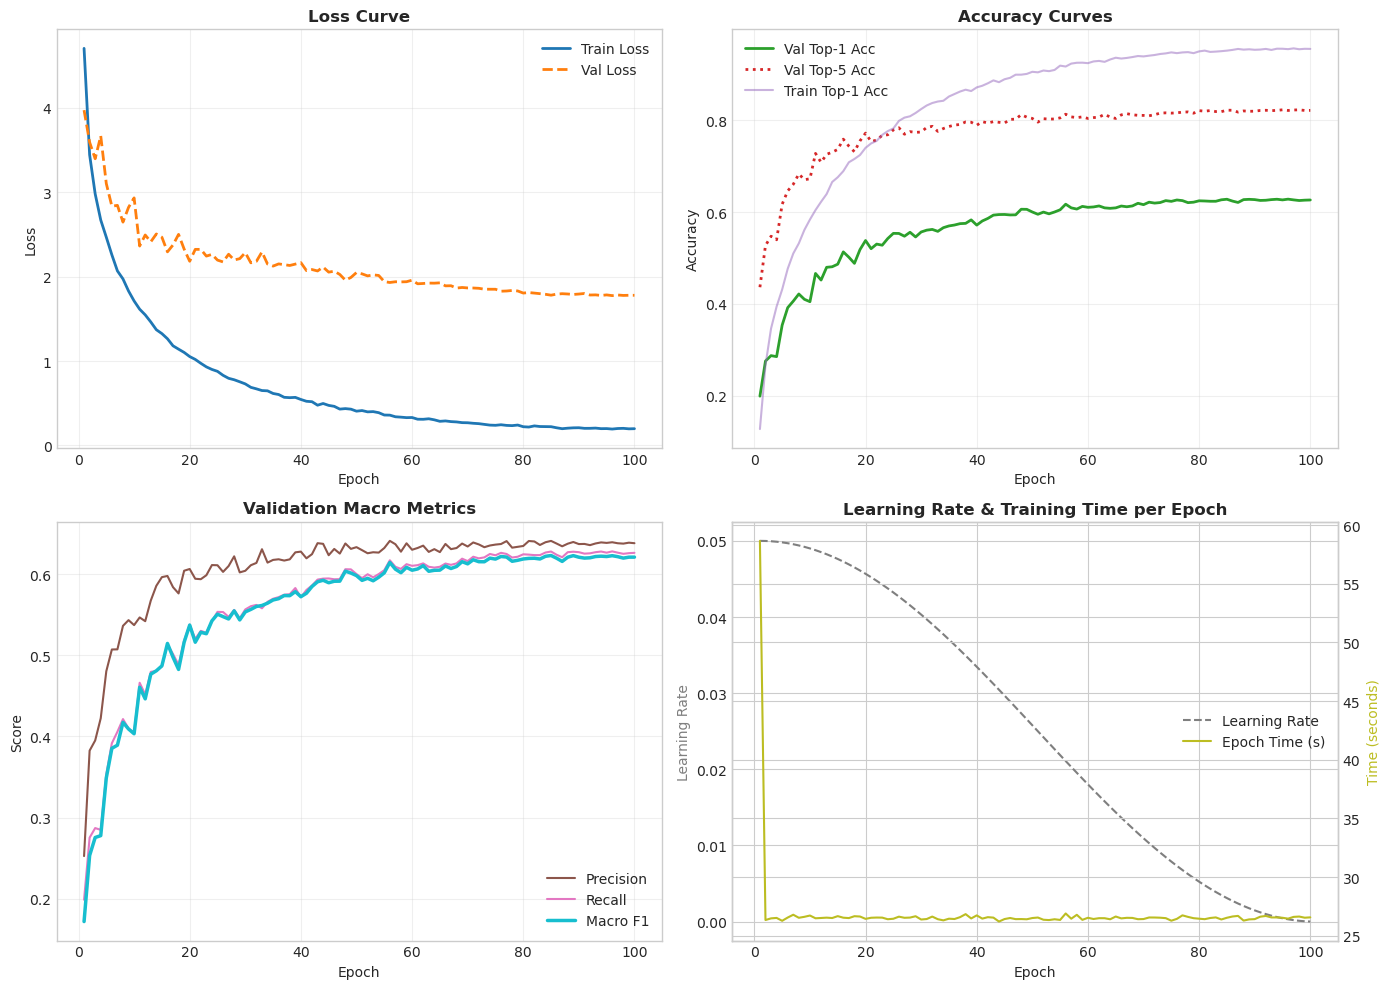

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Loss curve
axes[0, 0].plot(df_history['epoch'], df_history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[0, 0].plot(df_history['epoch'], df_history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0, 0].set_title('Loss Curve', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Top-1 & Top-5 accuracy curve
axes[0, 1].plot(df_history['epoch'], df_history['val_top1'], label='Val Top-1 Acc', color='#2ca02c', linewidth=2)
axes[0, 1].plot(df_history['epoch'], df_history['val_top5'], label='Val Top-5 Acc', color='#d62728', linewidth=2, linestyle=':')
axes[0, 1].plot(df_history['epoch'], df_history['train_top1'], label='Train Top-1 Acc', color='#9467bd', alpha=0.5)
axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Macro Precision, Recall, F1
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_precision'], label='Precision', color='#8c564b')
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_recall'], label='Recall', color='#e377c2')
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_f1'], label='Macro F1', color='#17becf', linewidth=2.5)
axes[1, 0].set_title('Validation Macro Metrics', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Score')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Learning rate and time consumption of single Epoch
ax_lr = axes[1, 1]
ax_time = ax_lr.twinx()

line1 = ax_lr.plot(df_history['epoch'], df_history['learning_rate'], color='#7f7f7f', label='Learning Rate', linestyle='--')
line2 = ax_time.plot(df_history['epoch'], df_history['train_seconds'] + df_history['val_seconds'], color='#bcbd22', label='Epoch Time (s)')

ax_lr.set_xlabel('Epoch')
ax_lr.set_ylabel('Learning Rate', color='#7f7f7f')
ax_time.set_ylabel('Time (seconds)', color='#bcbd22')
ax_lr.set_title('Learning Rate & Training Time per Epoch', fontsize=12, fontweight='bold')

# Merge legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax_lr.legend(lines, labels, loc='center right')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_training_curves.png"), dpi=300)
plt.show()

## Confidence & Error Analysis of prediction.

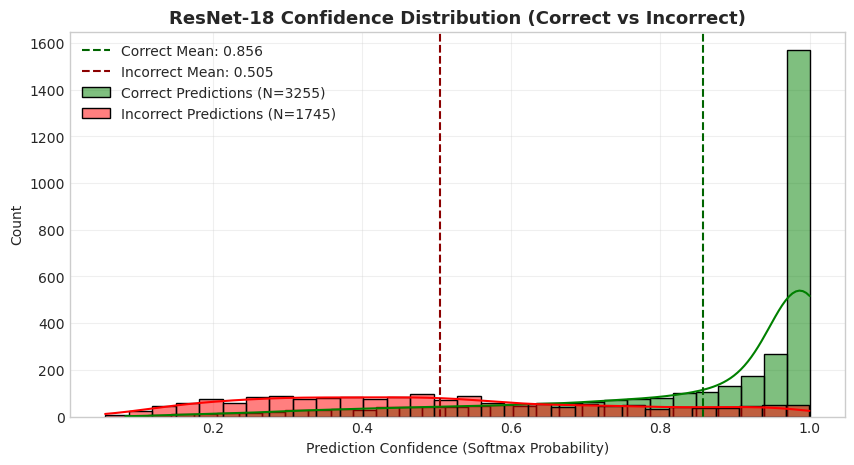

Average forecast confidence (overall): 0.7337
The average confidence of predicting correct samples.: 0.8564
Average confidence of prediction error samples: 0.5049


In [47]:
plt.figure(figsize=(10, 5))

# The confidence levels of prediction correctness and prediction error are extracted respectively.
correct_confs = df_preds[df_preds['is_correct'] == True]['confidence']
incorrect_confs = df_preds[df_preds['is_correct'] == False]['confidence']

sns.histplot(correct_confs, color='green', label=f'Correct Predictions (N={len(correct_confs)})', kde=True, bins=30, alpha=0.5)
sns.histplot(incorrect_confs, color='red', label=f'Incorrect Predictions (N={len(incorrect_confs)})', kde=True, bins=30, alpha=0.5)

plt.axvline(x=correct_confs.mean(), color='darkgreen', linestyle='--', label=f'Correct Mean: {correct_confs.mean():.3f}')
plt.axvline(x=incorrect_confs.mean(), color='darkred', linestyle='--', label=f'Incorrect Mean: {incorrect_confs.mean():.3f}')

plt.title('ResNet-18 Confidence Distribution (Correct vs Incorrect)', fontsize=13, fontweight='bold')
plt.xlabel('Prediction Confidence (Softmax Probability)')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(EXP_DIR, "resnet18_confidence_distribution.png"), dpi=300)
plt.show()

print(f"Average forecast confidence (overall): {df_preds['confidence'].mean():.4f}")
print(f"The average confidence of predicting correct samples.: {correct_confs.mean():.4f}")
print(f"Average confidence of prediction error samples: {incorrect_confs.mean():.4f}")

## Accuracy analysis of each category 

C:\Users\11625\AppData\Local\Temp\ipykernel_30740\1616325917.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
C:\Users\11625\AppData\Local\Temp\ipykernel_30740\1616325917.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])


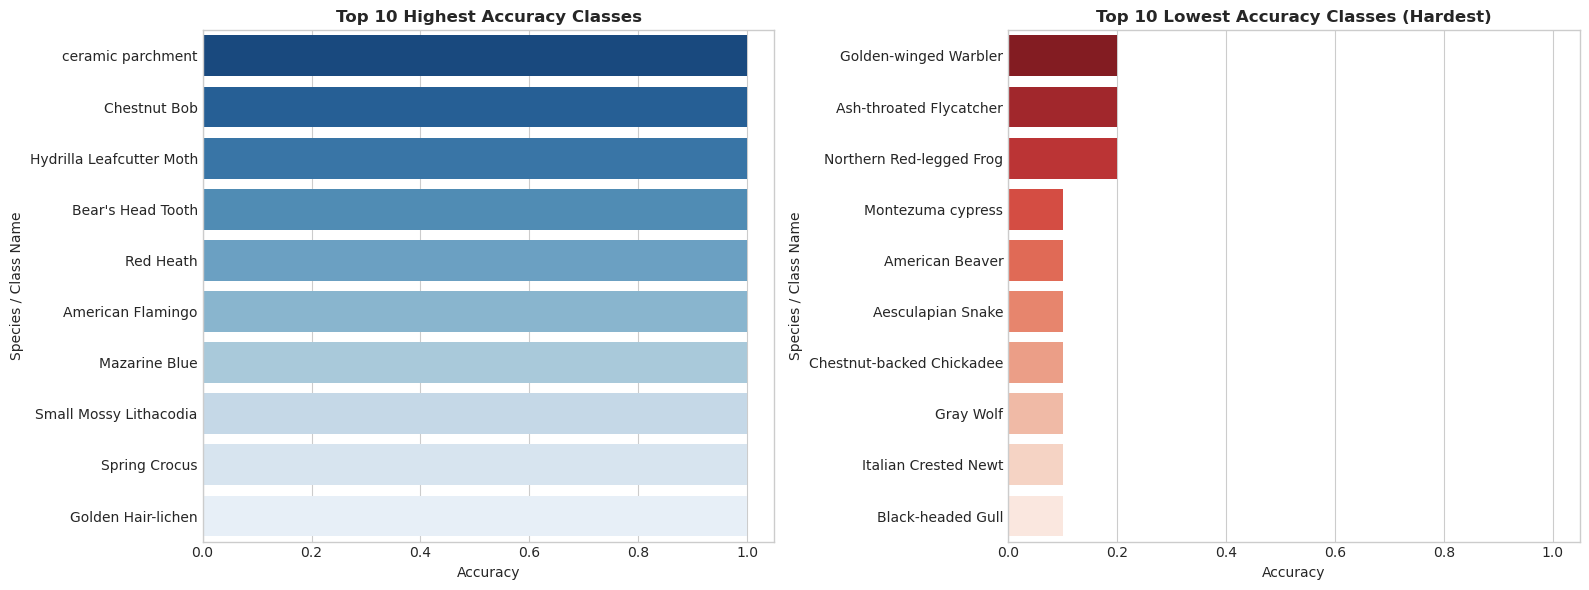

Number of categories with 100% accuracy: 40 / 500
The category with the lowest accuracy 'Golden-winged Warbler' (ID: 192): 20.0%


In [48]:
# Calculate the accuracy of each category
class_acc = df_preds.groupby('true_label')['is_correct'].mean().reset_index()
class_acc.columns = ['class_id', 'accuracy']

# Map class_id to real name (species name)
class_acc['class_name'] = class_acc['class_id'].map(idx_to_name)

# Sort by accuracy
class_acc_sorted = class_acc.sort_values(by='accuracy', ascending=False)

top_10 = class_acc_sorted.head(10)
bottom_10 = class_acc_sorted.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 most recognizable category (real name)
sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Highest Accuracy Classes', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Accuracy')
axes[0].set_ylabel('Species / Class Name')
axes[0].set_xlim(0, 1.05)

# Bottom 10 is the most difficult category to identify (real name)
sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])
axes[1].set_title('Top 10 Lowest Accuracy Classes (Hardest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Accuracy')
axes[1].set_ylabel('Species / Class Name')
axes[1].set_xlim(0, 1.05)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_per_class_accuracy.png"), dpi=300)
plt.show()

print(f"Number of categories with 100% accuracy: {(class_acc['accuracy'] == 1.0).sum()} / {len(class_acc)}")
print(f"The category with the lowest accuracy '{bottom_10.iloc[0]['class_name']}' (ID: {bottom_10.iloc[0]['class_id']}): {bottom_10.iloc[0]['accuracy']*100:.1f}%")

## Full Confusion Matrix Heatmap

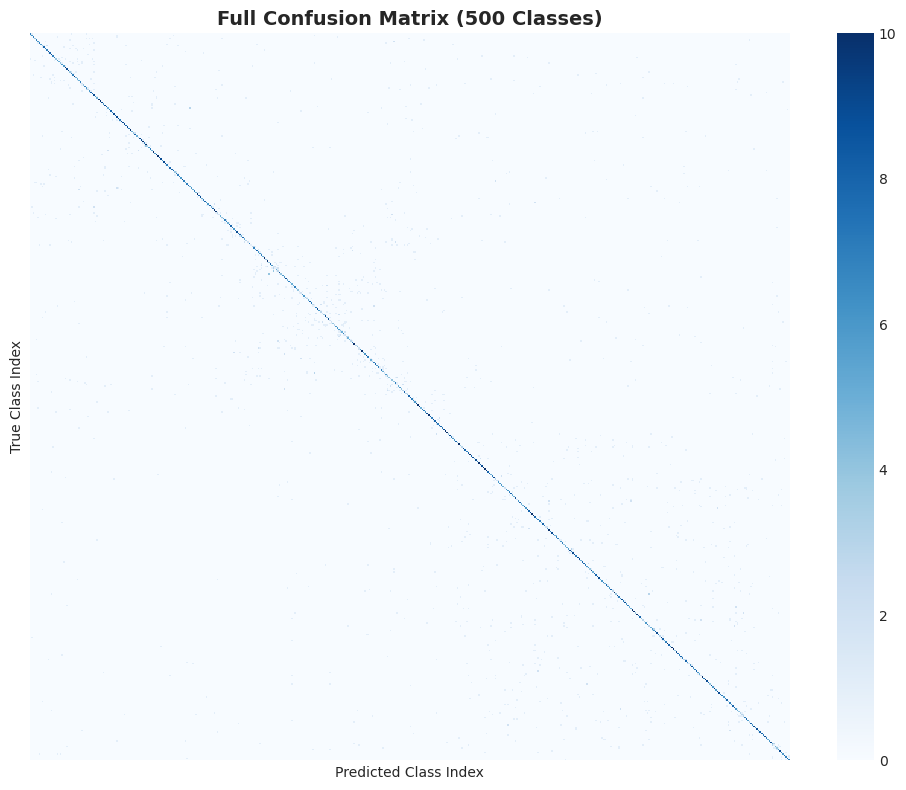

Confusion matrix dimension: (500, 500) (True x Pred)


In [49]:
# Determine the set of all category indexes
unique_labels = sorted(list(set(df_preds['true_label']).union(set(df_preds['pred_label']))))

# Calculate all-class confusion matrix
cm_full = confusion_matrix(df_preds['true_label'], df_preds['pred_label'], labels=unique_labels)

# Drawing total confusion matrix thermal diagram
plt.figure(figsize=(10, 8))
sns.heatmap(cm_full, cmap="Blues", cbar=True, xticklabels=False, yticklabels=False)
plt.title(f'Full Confusion Matrix ({len(unique_labels)} Classes)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class Index')
plt.ylabel('True Class Index')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_full_confusion_matrix.png"), dpi=300)
plt.show()

print(f"Confusion matrix dimension: {cm_full.shape} (True x Pred)")

## Fine-grained and Deep Analysis of Vulnerable Categories (Confusion Matrix of Vulnerable Category Subsets & Macro F1 Analysis)

Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy
 class_id                class_name  accuracy  precision  recall  f1-score
       34    Southern Carpenter Bee       0.2   0.285714     0.2  0.235294
      160           Hartlaub's Gull       0.2   0.166667     0.2  0.181818
      441              black willow       0.2   0.181818     0.2  0.190476
      198          Common Firecrest       0.2   0.400000     0.2  0.266667
      433         umbrella magnolia       0.2   0.500000     0.2  0.285714
      192     Golden-winged Warbler       0.2   0.333333     0.2  0.250000
      207   Ash-throated Flycatcher       0.2   0.200000     0.2  0.200000
      143  Northern Red-legged Frog       0.2   0.400000     0.2  0.266667
      489         Montezuma cypress       0.1   0.200000     0.1  0.133333
      230           American Beaver       0.1   0.142857     0.1  0.117647
      241         Aesculapian Snake       0.1   0.142857     0.1  0.117647
      187 Chestnut-backed 

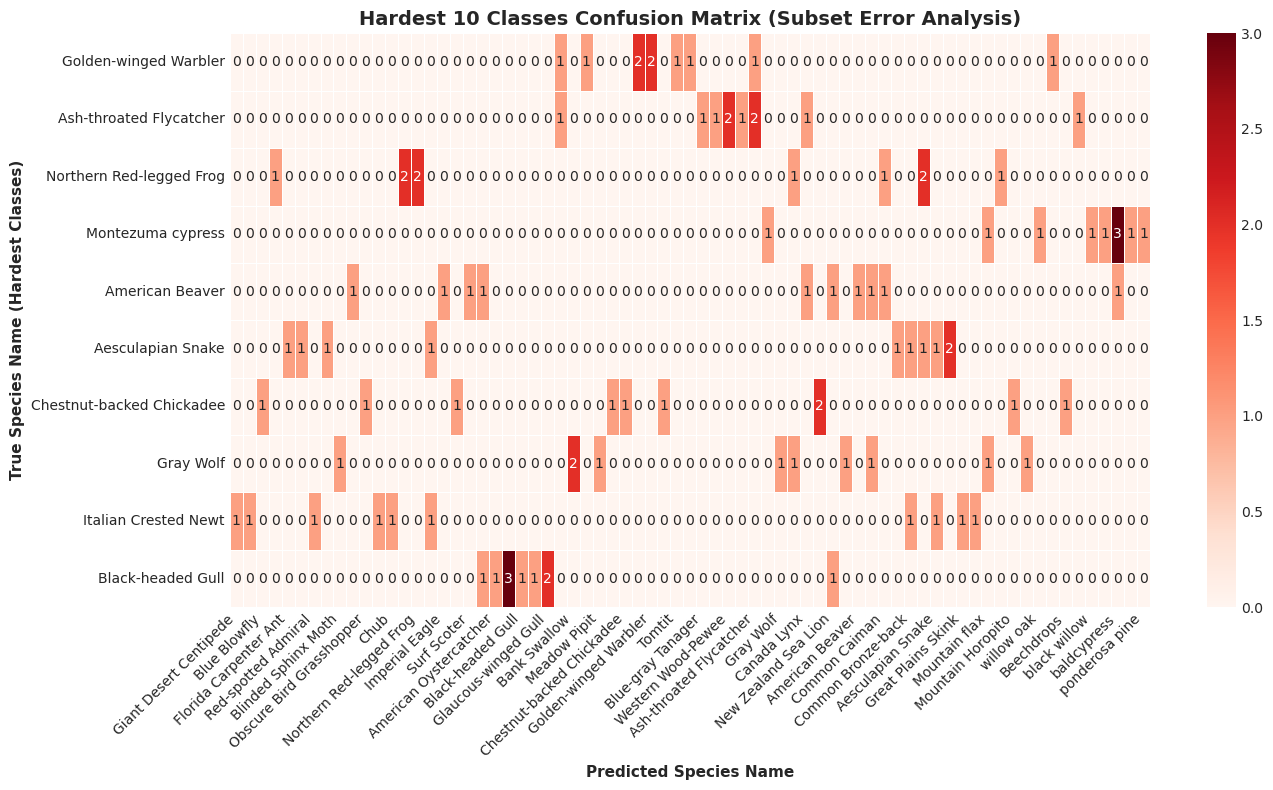

In [50]:
# Extract the weak categories Top-15 ranked from low to high in classification performance.
hardest_classes_df = class_acc_sorted.tail(15).copy()

# Generate a detailed classification evaluation report (Precision, Recall, F1) for these vulnerable categories.
report_dict = classification_report(
    df_preds['true_label'], 
    df_preds['pred_label'], 
    output_dict=True, 
    zero_division=0
)

# Add precision, recall and f1 to the weak category DataFrame.
hardest_classes_df['precision'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('precision', 0.0))
hardest_classes_df['recall'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('recall', 0.0))
hardest_classes_df['f1-score'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('f1-score', 0.0))

print("="*80)
print("Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy")
print("="*80)
display_cols = ['class_id', 'class_name', 'accuracy', 'precision', 'recall', 'f1-score']
print(hardest_classes_df[display_cols].to_string(index=False))
print("="*80)

# Extract the Top 10 vulnerable categories and their common confusing target categories, and construct a subset confusion matrix.
hardest_10_ids = class_acc_sorted.tail(10)['class_id'].tolist()

# Filter out the prediction results of test sets whose real labels belong to these 10 weak categories.
sub_preds = df_preds[df_preds['true_label'].isin(hardest_10_ids)].copy()

# Get all the prediction categories involved in this batch of samples (including other categories that they have been misjudged)
relevant_pred_ids = sorted(list(set(sub_preds['true_label']).union(set(sub_preds['pred_label']))))

# Computing subset confusion matrix
cm_sub = confusion_matrix(sub_preds['true_label'], sub_preds['pred_label'], labels=relevant_pred_ids)

# The mapping axis shows the real name.
row_names = [idx_to_name[i] for i in hardest_10_ids]
col_names = [idx_to_name[i] for i in relevant_pred_ids]

# Find the subscript index containing the confusion matrix of this subset, and generate the drawing matrix.
sub_matrix_display = pd.DataFrame(cm_sub, index=[idx_to_name[i] for i in relevant_pred_ids], columns=col_names)
sub_matrix_display = sub_matrix_display.loc[row_names]

# Heat map of drawing confusion matrix of weak category subset
plt.figure(figsize=(14, 8))
sns.heatmap(sub_matrix_display, annot=True, fmt="d", cmap="Reds", cbar=True, linewidths=0.5)

plt.title('Hardest 10 Classes Confusion Matrix (Subset Error Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Species Name', fontsize=11, fontweight='bold')
plt.ylabel('True Species Name (Hardest Classes)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_hardest_classes_confusion_matrix.png"), dpi=300)
plt.show()

# EfficientNet-B0 Pretrained Analysis

## Environment import and basic configuration, file path initialization and category name mapping loading

In [51]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Set the global drawing style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'SimHei']  # SimHei
plt.rcParams['axes.unicode_minus'] = False

# Destination folder path and metadata path
EXP_DIR = os.path.join("experiment_workspace", "D_member_outputs", "efficientnet_b0_pretrained")
CLASS_MAPPING_PATH = os.path.join("data_metadata", "class_to_idx.json")
SELECTED_CLASSES_PATH = os.path.join("data_metadata", "selected_classes.json")

# Verify the integrity of the core output file
required_files = ["training_history.csv", "test_metrics.json", "test_predictions.csv", "test_scores.npz", "class_mapping.json"]
for f in required_files:
    file_path = os.path.join(EXP_DIR, f)
    assert os.path.exists(file_path), f"Key file not found.: {file_path}"

# 2.  original_category_id -> true name -> class_index
with open(SELECTED_CLASSES_PATH, "r", encoding="utf-8") as f:
    selected_classes_data = json.load(f)

# build original_category_id -> true name 
id_to_name = {
    str(item["original_category_id"]): item.get("common_name") or item.get("species")
    for item in selected_classes_data
}

# load category_id -> class_index 
with open(CLASS_MAPPING_PATH, "r", encoding="utf-8") as f:
    class_mapping = json.load(f)

# build class_index -> true name 
idx_to_name = {}
for orig_id, class_idx in class_mapping.items():
    name = id_to_name.get(str(orig_id), f"Class {class_idx}")
    idx_to_name[int(class_idx)] = name

print(f"All the required documents are ready! working directory: {EXP_DIR}")
print(f"The real names of {len(idx_to_name)} categories were successfully extracted and mapped.")

All the required documents are ready! working directory: experiment_workspace\D_member_outputs\efficientnet_b0_pretrained
The real names of 500 categories were successfully extracted and mapped.


## Loading data and printing core test Metrics Overview.

In [53]:
# 1. load Metrics JSON
with open(os.path.join(EXP_DIR, "test_metrics.json"), "r", encoding="utf-8") as f:
    test_metrics = json.load(f)

# 2. load Predictions CSV
df_preds = pd.read_csv(os.path.join(EXP_DIR, "test_predictions.csv"))

# 3. load History CSV
df_history = pd.read_csv(os.path.join(EXP_DIR, "training_history.csv"))

# 4. load NPZ Scores
npz_data = np.load(os.path.join(EXP_DIR, "test_scores.npz"))
test_scores = npz_data["scores"]

print("="*50)
print("Summary of core performance of EfficientNet-B0 Pretrained test set")
print("="*50)
print(f"• Top-1 Accuracy    : {test_metrics['top1_accuracy']*100:.2f}%")
print(f"• Top-5 Accuracy    : {test_metrics['top5_accuracy']*100:.2f}%")
print(f"• Macro Precision   : {test_metrics['macro_precision']:.4f}")
print(f"• Macro Recall      : {test_metrics['macro_recall']:.4f}")
print(f"• Macro F1-Score    : {test_metrics['macro_f1']:.4f}")
print(f"• Weighted F1-Score : {test_metrics['weighted_f1']:.4f}")
print(f"• Test Loss         : {test_metrics['loss']:.4f}")
print(f"• Training Time     : {test_metrics['training_time_seconds']/60:.2f} min ({test_metrics['training_time_seconds']:.1f}s)")
print(f"• Inference Time    : {test_metrics['inference_time_seconds']:.2f}s")
print("="*50)

Summary of core performance of EfficientNet-B0 Pretrained test set
• Top-1 Accuracy    : 76.66%
• Top-5 Accuracy    : 90.50%
• Macro Precision   : 0.7763
• Macro Recall      : 0.7666
• Macro F1-Score    : 0.7620
• Weighted F1-Score : 0.7620
• Test Loss         : 1.0509
• Training Time     : 79.11 min (4746.8s)
• Inference Time    : 5.99s


## Draw and save the Training Curves.

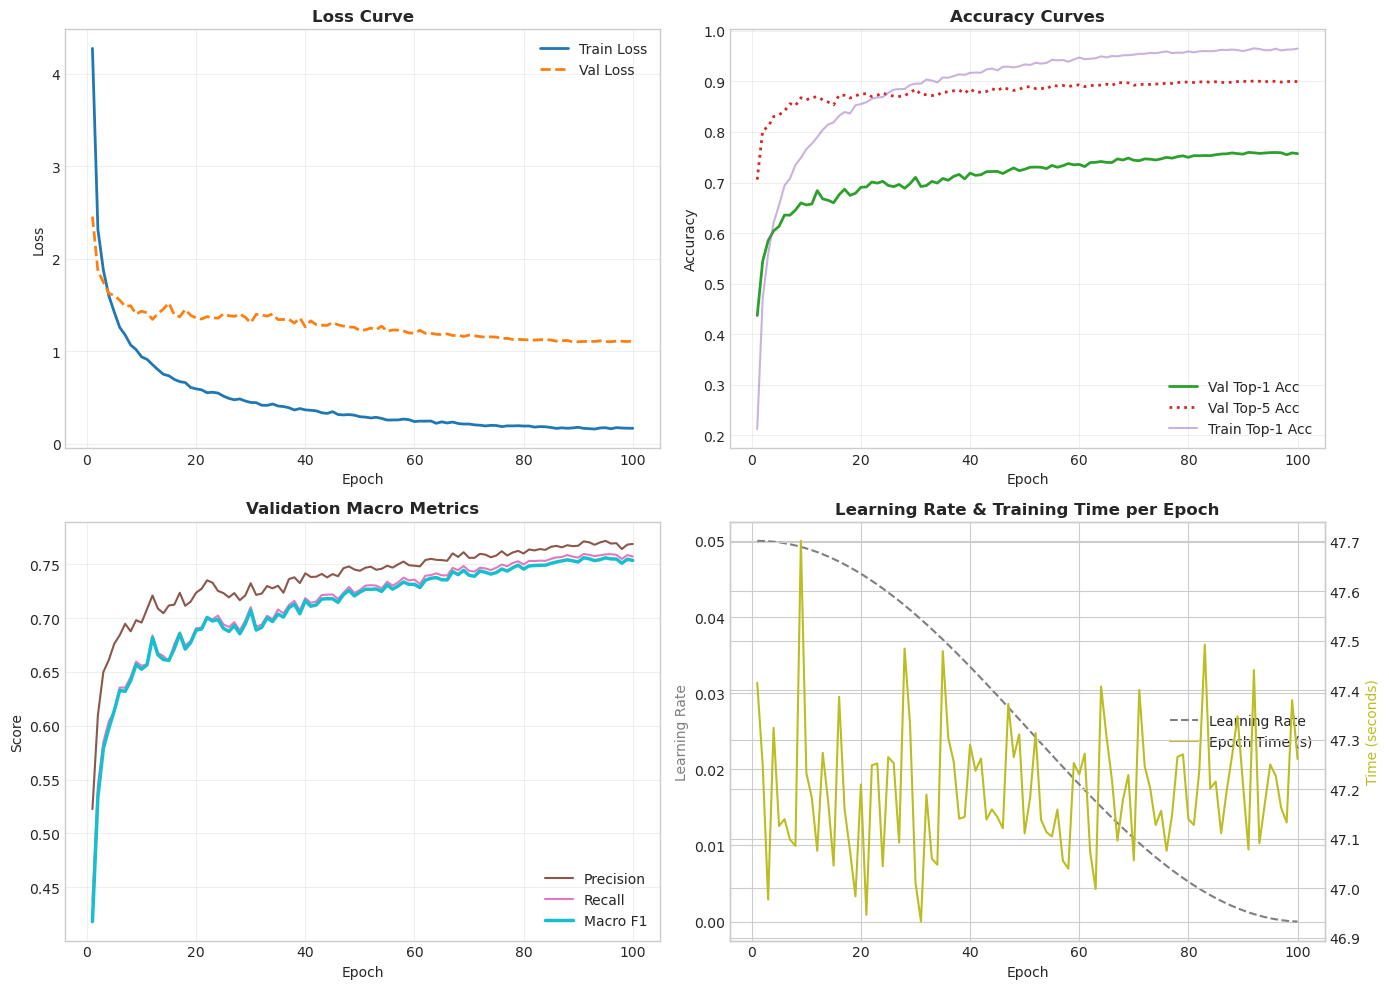

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss Curve
axes[0, 0].plot(df_history['epoch'], df_history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[0, 0].plot(df_history['epoch'], df_history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0, 0].set_title('Loss Curve', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Top-1 & Top-5 accuracy Curve
axes[0, 1].plot(df_history['epoch'], df_history['val_top1'], label='Val Top-1 Acc', color='#2ca02c', linewidth=2)
axes[0, 1].plot(df_history['epoch'], df_history['val_top5'], label='Val Top-5 Acc', color='#d62728', linewidth=2, linestyle=':')
axes[0, 1].plot(df_history['epoch'], df_history['train_top1'], label='Train Top-1 Acc', color='#9467bd', alpha=0.5)
axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Macro Precision, Recall, F1
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_precision'], label='Precision', color='#8c564b')
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_recall'], label='Recall', color='#e377c2')
axes[1, 0].plot(df_history['epoch'], df_history['val_macro_f1'], label='Macro F1', color='#17becf', linewidth=2.5)
axes[1, 0].set_title('Validation Macro Metrics', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Score')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning rate and time consumption of single Epoch
ax_lr = axes[1, 1]
ax_time = ax_lr.twinx()

line1 = ax_lr.plot(df_history['epoch'], df_history['learning_rate'], color='#7f7f7f', label='Learning Rate', linestyle='--')
line2 = ax_time.plot(df_history['epoch'], df_history['train_seconds'] + df_history['val_seconds'], color='#bcbd22', label='Epoch Time (s)')

ax_lr.set_xlabel('Epoch')
ax_lr.set_ylabel('Learning Rate', color='#7f7f7f')
ax_time.set_ylabel('Time (seconds)', color='#bcbd22')
ax_lr.set_title('Learning Rate & Training Time per Epoch', fontsize=12, fontweight='bold')

# Merge legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax_lr.legend(lines, labels, loc='center right')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "EfficientNetB0_training_curves.png"), dpi=300)
plt.show()

## Confidence & Error Analysis of prediction.

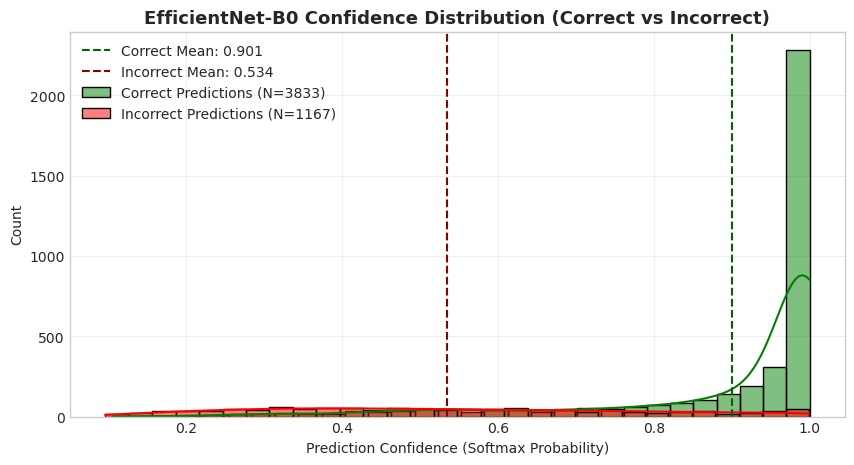

Average forecast confidence (overall): 0.8151
The average confidence of predicting correct samples.: 0.9006
Average confidence of prediction error samples: 0.5343


In [55]:
plt.figure(figsize=(10, 5))

# respectively extract the confidence of correct prediction and wrong prediction.
correct_confs = df_preds[df_preds['is_correct'] == True]['confidence']
incorrect_confs = df_preds[df_preds['is_correct'] == False]['confidence']

sns.histplot(correct_confs, color='green', label=f'Correct Predictions (N={len(correct_confs)})', kde=True, bins=30, alpha=0.5)
sns.histplot(incorrect_confs, color='red', label=f'Incorrect Predictions (N={len(incorrect_confs)})', kde=True, bins=30, alpha=0.5)

plt.axvline(x=correct_confs.mean(), color='darkgreen', linestyle='--', label=f'Correct Mean: {correct_confs.mean():.3f}')
plt.axvline(x=incorrect_confs.mean(), color='darkred', linestyle='--', label=f'Incorrect Mean: {incorrect_confs.mean():.3f}')

plt.title('EfficientNet-B0 Confidence Distribution (Correct vs Incorrect)', fontsize=13, fontweight='bold')
plt.xlabel('Prediction Confidence (Softmax Probability)')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(EXP_DIR, "EfficientNetB0_confidence_distribution.png"), dpi=300)
plt.show()

print(f"Average forecast confidence (overall): {df_preds['confidence'].mean():.4f}")
print(f"The average confidence of predicting correct samples.: {correct_confs.mean():.4f}")
print(f"Average confidence of prediction error samples: {incorrect_confs.mean():.4f}")

## Accuracy analysis of various categories

C:\Users\11625\AppData\Local\Temp\ipykernel_30740\2211578050.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
C:\Users\11625\AppData\Local\Temp\ipykernel_30740\2211578050.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])


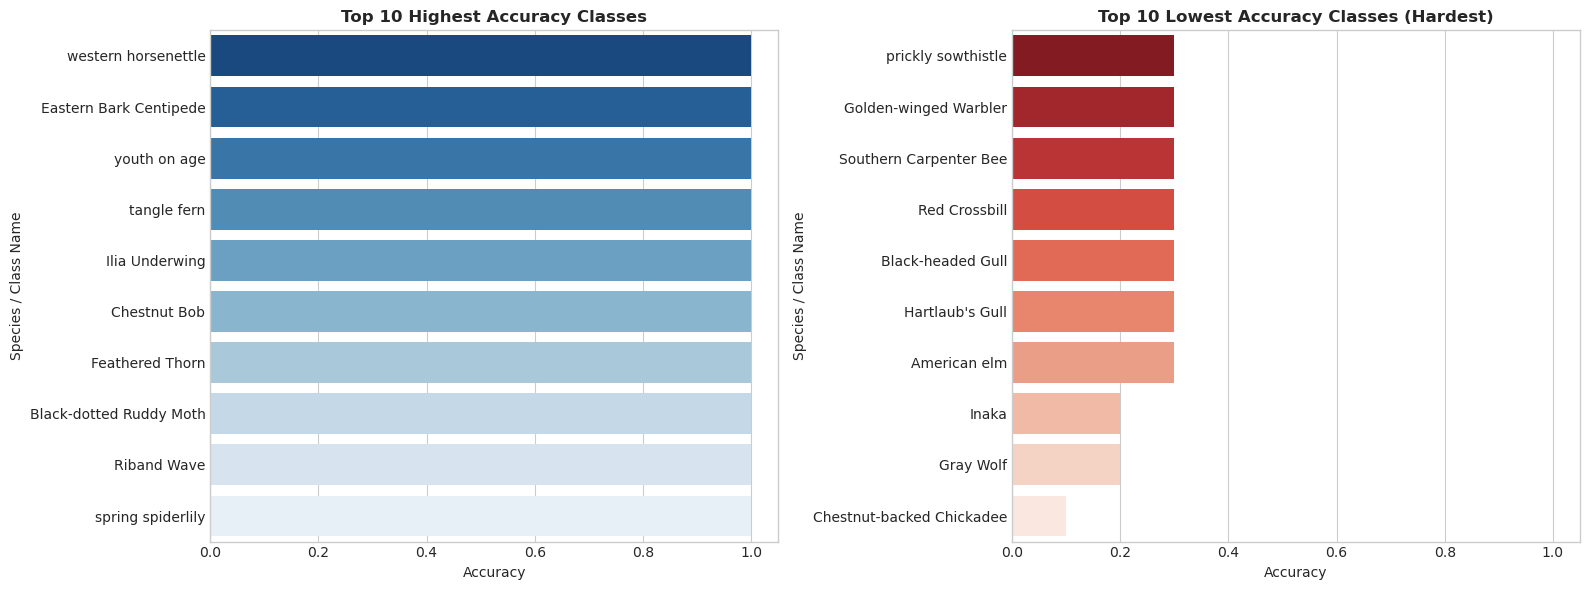

Number of categories with 100% accuracy: 81 / 500
The category with the lowest accuracy 'prickly sowthistle' (ID: 339): 30.0%


In [56]:
# Calculate the accuracy of each category
class_acc = df_preds.groupby('true_label')['is_correct'].mean().reset_index()
class_acc.columns = ['class_id', 'accuracy']

# Map class_id to real name (species name)
class_acc['class_name'] = class_acc['class_id'].map(idx_to_name)

# Sort by accuracy
class_acc_sorted = class_acc.sort_values(by='accuracy', ascending=False)

top_10 = class_acc_sorted.head(10)
bottom_10 = class_acc_sorted.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 most recognizable category (real name)
sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Highest Accuracy Classes', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Accuracy')
axes[0].set_ylabel('Species / Class Name')
axes[0].set_xlim(0, 1.05)

# Bottom 10 is the most difficult category to identify (real name)
sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])
axes[1].set_title('Top 10 Lowest Accuracy Classes (Hardest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Accuracy')
axes[1].set_ylabel('Species / Class Name')
axes[1].set_xlim(0, 1.05)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "EfficientNetB0_per_class_accuracy.png"), dpi=300)
plt.show()

print(f"Number of categories with 100% accuracy: {(class_acc['accuracy'] == 1.0).sum()} / {len(class_acc)}")
print(f"The category with the lowest accuracy '{bottom_10.iloc[0]['class_name']}' (ID: {bottom_10.iloc[0]['class_id']}): {bottom_10.iloc[0]['accuracy']*100:.1f}%")

## Full Confusion Matrix Heatmap

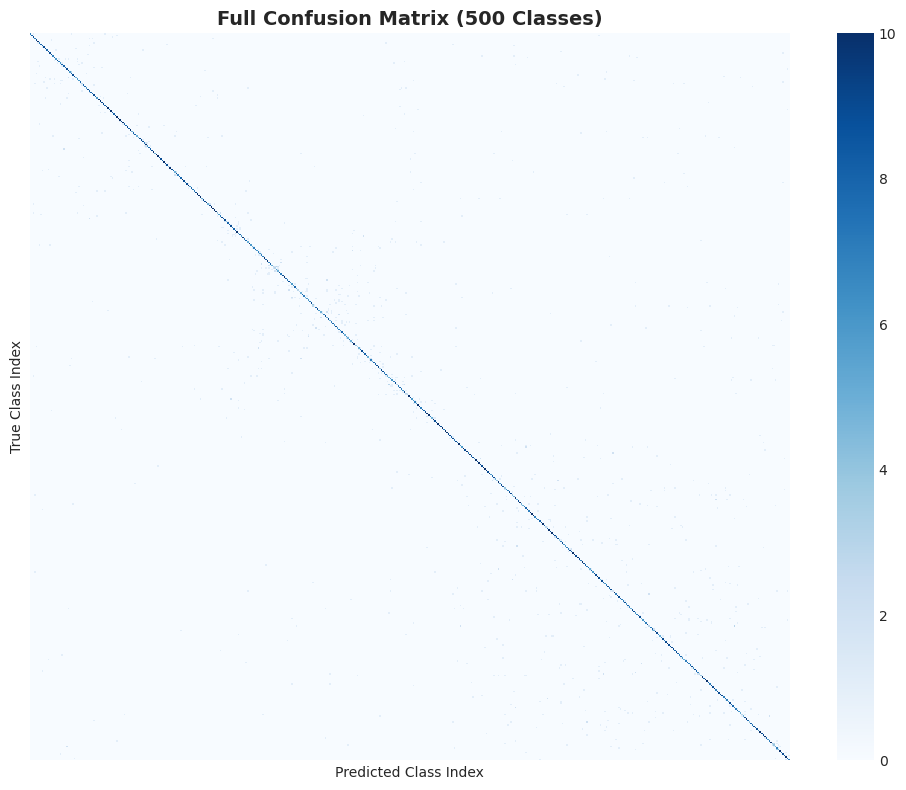

Confusion matrix dimension: (500, 500) (True x Pred)


In [57]:
# Determine the set of all category indexes
unique_labels = sorted(list(set(df_preds['true_label']).union(set(df_preds['pred_label']))))

# Calculate all-class confusion matrix
cm_full = confusion_matrix(df_preds['true_label'], df_preds['pred_label'], labels=unique_labels)

# Drawing total confusion matrix thermal diagram
plt.figure(figsize=(10, 8))
sns.heatmap(cm_full, cmap="Blues", cbar=True, xticklabels=False, yticklabels=False)
plt.title(f'Full Confusion Matrix ({len(unique_labels)} Classes)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class Index')
plt.ylabel('True Class Index')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "EfficientNetB0_full_confusion_matrix.png"), dpi=300)
plt.show()

print(f"Confusion matrix dimension: {cm_full.shape} (True x Pred)")

## Fine-grained and Deep Analysis of Vulnerable Categories (Confusion Matrix of Vulnerable Category Subsets & Macro F1 Analysis)

Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy
 class_id                class_name  accuracy  precision  recall  f1-score
      440               Grey Willow       0.3   0.600000     0.3  0.400000
      215       Eastern Screech-Owl       0.3   0.300000     0.3  0.300000
      407           Coprosma dumosa       0.3   0.428571     0.3  0.352941
      247       Western Rattlesnake       0.3   0.300000     0.3  0.300000
      248                Massasauga       0.3   0.600000     0.3  0.400000
      339        prickly sowthistle       0.3   0.750000     0.3  0.428571
      192     Golden-winged Warbler       0.3   0.750000     0.3  0.428571
       34    Southern Carpenter Bee       0.3   0.500000     0.3  0.375000
      176             Red Crossbill       0.3   1.000000     0.3  0.461538
      161         Black-headed Gull       0.3   0.333333     0.3  0.315789
      160           Hartlaub's Gull       0.3   0.500000     0.3  0.375000
      468              Ame

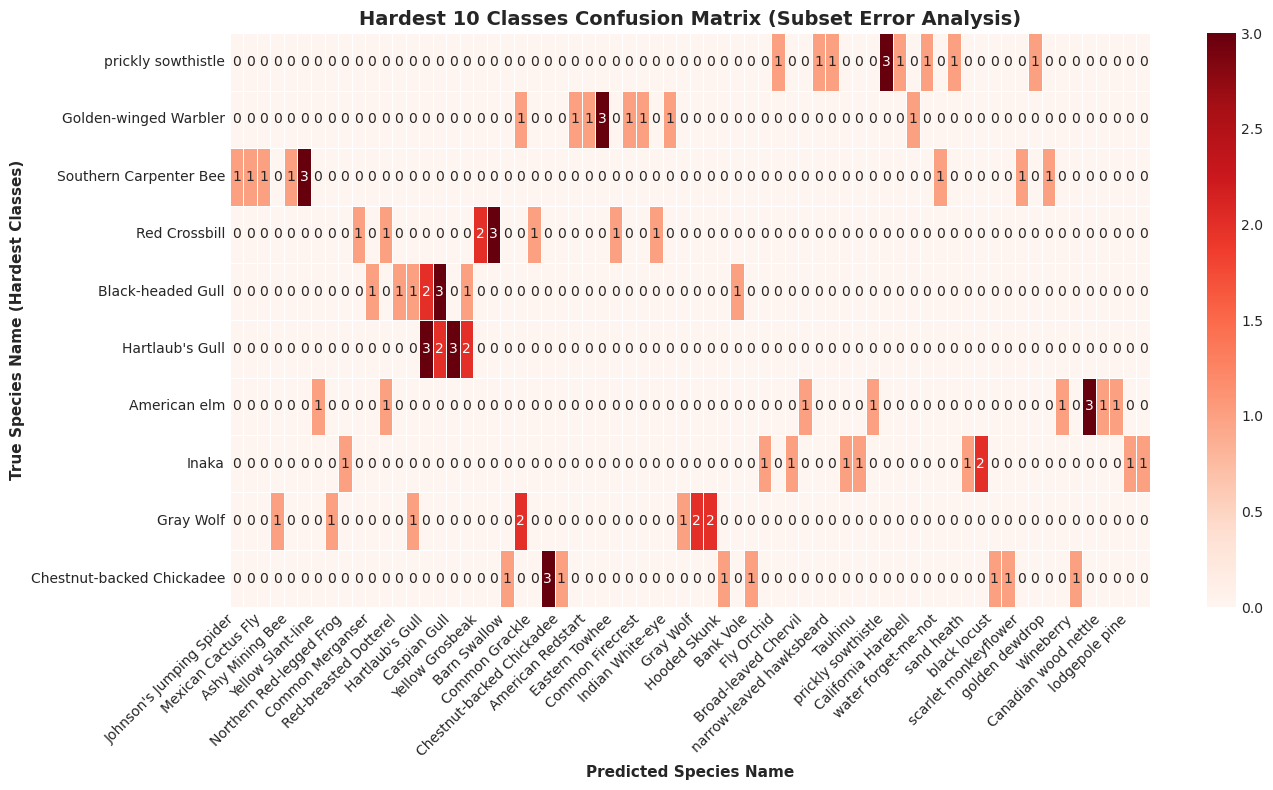

In [58]:
# Extract the weak categories Top-15 ranked from low to high in classification performance.
hardest_classes_df = class_acc_sorted.tail(15).copy()

# Generate a detailed classification evaluation report (Precision, Recall, F1) for these vulnerable categories.
report_dict = classification_report(
    df_preds['true_label'], 
    df_preds['pred_label'], 
    output_dict=True, 
    zero_division=0
)

# Supplementary Accuracy, Recall, F1 to Vulnerable Category Data Frame
hardest_classes_df['precision'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('precision', 0.0))
hardest_classes_df['recall'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('recall', 0.0))
hardest_classes_df['f1-score'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('f1-score', 0.0))

print("="*80)
print("Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy")
print("="*80)
display_cols = ['class_id', 'class_name', 'accuracy', 'precision', 'recall', 'f1-score']
print(hardest_classes_df[display_cols].to_string(index=False))
print("="*80)

# Extract the Top 10 vulnerable categories and their common confusing target categories, and construct a subset confusion matrix.
hardest_10_ids = class_acc_sorted.tail(10)['class_id'].tolist()

# Filter out the prediction results of test sets whose real labels belong to these 10 weak categories.
sub_preds = df_preds[df_preds['true_label'].isin(hardest_10_ids)].copy()

# Get all the prediction categories involved in this batch of samples (including other categories that they have been misjudged)
relevant_pred_ids = sorted(list(set(sub_preds['true_label']).union(set(sub_preds['pred_label']))))

# Computing subset confusion matrix
cm_sub = confusion_matrix(sub_preds['true_label'], sub_preds['pred_label'], labels=relevant_pred_ids)

# The mapping axis shows the real name.
row_names = [idx_to_name[i] for i in hardest_10_ids]
col_names = [idx_to_name[i] for i in relevant_pred_ids]

# Find the subscript index containing the confusion matrix of this subset, and generate the drawing matrix.
sub_matrix_display = pd.DataFrame(cm_sub, index=[idx_to_name[i] for i in relevant_pred_ids], columns=col_names)
sub_matrix_display = sub_matrix_display.loc[row_names]

# Heat map of drawing confusion matrix of weak category subset
plt.figure(figsize=(14, 8))
sns.heatmap(sub_matrix_display, annot=True, fmt="d", cmap="Reds", cbar=True, linewidths=0.5)

plt.title('Hardest 10 Classes Confusion Matrix (Subset Error Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Species Name', fontsize=11, fontweight='bold')
plt.ylabel('True Species Name (Hardest Classes)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "EfficientNetB0_hardest_classes_confusion_matrix.png"), dpi=300)
plt.show()

# ResNet-18 Scratch Analysis

## Environment import and basic configuration, file path initialization and category name mapping loading

predictions_test.csv, metrics_test.json, history.csv, c1_test_scores.npz should under the path: experiment_workspace\C_member_outputs\predictions

In [61]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Set the global drawing style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

# Target folder and metadata path settings
EXP_DIR = os.path.join("experiment_workspace", "C_member_outputs", "predictions")
META_DIR = "data_metadata"

CLASS_MAPPING_PATH = os.path.join(META_DIR, "class_to_idx.json")
SELECTED_CLASSES_PATH = os.path.join(META_DIR, "selected_classes.json")

#Verify the integrity of key input files
required_files = ["c1_test_scores.npz", "history.csv", "metrics_test.json", "predictions_test.csv"]
for f in required_files:
    file_path = os.path.join(EXP_DIR, f)
    assert os.path.exists(file_path), f"Key file not found.: {file_path}"

assert os.path.exists(CLASS_MAPPING_PATH), f"Could not find the category index mapping file.: {CLASS_MAPPING_PATH}"
assert os.path.exists(SELECTED_CLASSES_PATH), f"Metadata file not found.: {SELECTED_CLASSES_PATH}"

# Load class_to_idx and set up real name mapping with selected_classes.
with open(SELECTED_CLASSES_PATH, "r", encoding="utf-8") as f:
    selected_classes_data = json.load(f)

# Construct the original_category_id-> common name/categories mapping.
id_to_name = {}
for item in selected_classes_data:
    cat_id = str(item.get("original_category_id", item.get("category_id", "")))
    name = item.get("common_name") or item.get("species") or f"Category {cat_id}"
    id_to_name[cat_id] = name

# load class_to_idx.json
with open(CLASS_MAPPING_PATH, "r", encoding="utf-8") as f:
    class_to_idx = json.load(f)

# build class_index (int) -> common name
idx_to_name = {}
for key, val in class_to_idx.items():
    if isinstance(val, int) or (isinstance(val, str) and str(val).isdigit()):
        c_idx = int(val)
        c_name = id_to_name.get(str(key), str(key))
        idx_to_name[c_idx] = c_name
    else:
        c_idx = int(key)
        c_name = id_to_name.get(str(val), str(val))
        idx_to_name[c_idx] = c_name

print(f"[ResNet-18 Scratch] All documents have been verified! working directory: {EXP_DIR}")
print(f"Successfully extracted and mapped the real names of {len(idx_to_name)} categories.")

[ResNet-18 Scratch] All documents have been verified! working directory: experiment_workspace\C_member_outputs\predictions
Successfully extracted and mapped the real names of 500 categories.


## Loading data and printing core test Metrics Overview.

In [62]:
# load metrics_test.json
with open(os.path.join(EXP_DIR, "metrics_test.json"), "r", encoding="utf-8") as f:
    test_metrics = json.load(f)

# load predictions_test.csv
df_preds = pd.read_csv(os.path.join(EXP_DIR, "predictions_test.csv"))
if 'is_correct' not in df_preds.columns and 'true_label' in df_preds.columns and 'predicted_class' in df_preds.columns:
    df_preds['is_correct'] = df_preds['true_label'] == df_preds['predicted_class']

# load history.csv
df_history = pd.read_csv(os.path.join(EXP_DIR, "history.csv"))

# load c1_test_scores.npz
npz_data = np.load(os.path.join(EXP_DIR, "c1_test_scores.npz"))
test_scores = npz_data[npz_data.files[0]]

# Secure Access Indicator Fields
top1 = test_metrics.get('top1_accuracy', test_metrics.get('top1_acc', test_metrics.get('accuracy', 0.0)))
top5 = test_metrics.get('top5_accuracy', test_metrics.get('top5_acc', 0.0))
precision = test_metrics.get('macro_precision', 0.0)
recall = test_metrics.get('macro_recall', 0.0)
f1_macro = test_metrics.get('macro_f1', 0.0)
f1_weighted = test_metrics.get('weighted_f1', 0.0)
loss = test_metrics.get('loss', test_metrics.get('test_loss', 0.0))
train_time = test_metrics.get('training_time_seconds', test_metrics.get('total_train_time', 0.0))
infer_time = test_metrics.get('inference_time_seconds', test_metrics.get('test_time', 0.0))

print("="*55)
print("Summary of Core Performance of ResNet-18 (Scratch) Test Set")
print("="*55)
print(f"• Top-1 Accuracy    : {top1*100:.2f}%")
print(f"• Top-5 Accuracy    : {top5*100:.2f}%")
print(f"• Macro Precision   : {precision:.4f}")
print(f"• Macro Recall      : {recall:.4f}")
print(f"• Macro F1-Score    : {f1_macro:.4f}")
print(f"• Weighted F1-Score : {f1_weighted:.4f}")
print(f"• Test Loss         : {loss:.4f}")
if train_time > 0:
    print(f"• Training Time     : {train_time/60:.2f} min ({train_time:.1f}s)")
if infer_time > 0:
    print(f"• Inference Time    : {infer_time:.2f}s")
print("="*55)

Summary of Core Performance of ResNet-18 (Scratch) Test Set
• Top-1 Accuracy    : 41.32%
• Top-5 Accuracy    : 64.16%
• Macro Precision   : 0.4140
• Macro Recall      : 0.4132
• Macro F1-Score    : 0.4045
• Weighted F1-Score : 0.0000
• Test Loss         : 3.3001


## Draw a Training & Validation History.

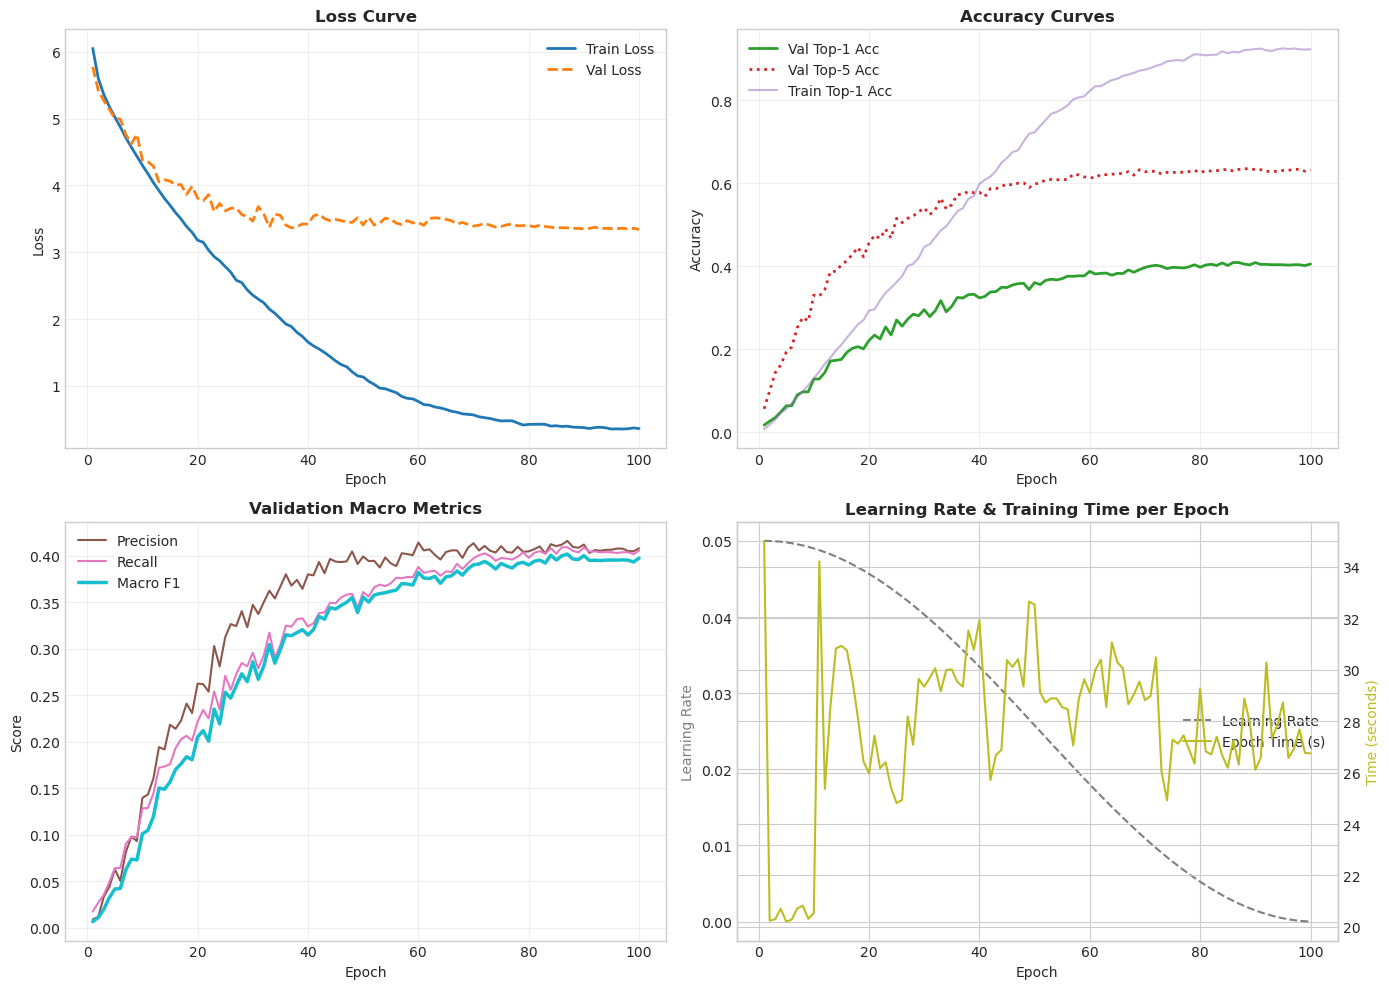

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss curve
if 'train_loss' in df_history.columns and 'val_loss' in df_history.columns:
    axes[0, 0].plot(df_history['epoch'], df_history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
    axes[0, 0].plot(df_history['epoch'], df_history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0, 0].set_title('Loss Curve', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy curve
if 'val_top1' in df_history.columns:
    axes[0, 1].plot(df_history['epoch'], df_history['val_top1'], label='Val Top-1 Acc', color='#2ca02c', linewidth=2)
if 'val_top5' in df_history.columns:
    axes[0, 1].plot(df_history['epoch'], df_history['val_top5'], label='Val Top-5 Acc', color='#d62728', linewidth=2, linestyle=':')
if 'train_top1' in df_history.columns:
    axes[0, 1].plot(df_history['epoch'], df_history['train_top1'], label='Train Top-1 Acc', color='#9467bd', alpha=0.5)
axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Macro Metrics curve
if 'val_macro_precision' in df_history.columns:
    axes[1, 0].plot(df_history['epoch'], df_history['val_macro_precision'], label='Precision', color='#8c564b')
if 'val_macro_recall' in df_history.columns:
    axes[1, 0].plot(df_history['epoch'], df_history['val_macro_recall'], label='Recall', color='#e377c2')
if 'val_macro_f1' in df_history.columns:
    axes[1, 0].plot(df_history['epoch'], df_history['val_macro_f1'], label='Macro F1', color='#17becf', linewidth=2.5)
axes[1, 0].set_title('Validation Macro Metrics', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Score')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning rate and Epoch time-consuming
ax_lr = axes[1, 1]
ax_time = ax_lr.twinx()

lines = []
if 'learning_rate' in df_history.columns or 'lr' in df_history.columns:
    lr_col = 'learning_rate' if 'learning_rate' in df_history.columns else 'lr'
    line1 = ax_lr.plot(df_history['epoch'], df_history[lr_col], color='#7f7f7f', label='Learning Rate', linestyle='--')
    lines += line1

time_cols = [c for c in ['train_seconds', 'val_seconds'] if c in df_history.columns]
if time_cols:
    epoch_time = df_history[time_cols].sum(axis=1)
    line2 = ax_time.plot(df_history['epoch'], epoch_time, color='#bcbd22', label='Epoch Time (s)')
    lines += line2

ax_lr.set_xlabel('Epoch')
ax_lr.set_ylabel('Learning Rate', color='#7f7f7f')
ax_time.set_ylabel('Time (seconds)', color='#bcbd22')
ax_lr.set_title('Learning Rate & Training Time per Epoch', fontsize=12, fontweight='bold')

if lines:
    labels = [l.get_label() for l in lines]
    ax_lr.legend(lines, labels, loc='center right')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_scratch_training_curves.png"), dpi=300)
plt.show()

## Confidence & Error Analysis of prediction.

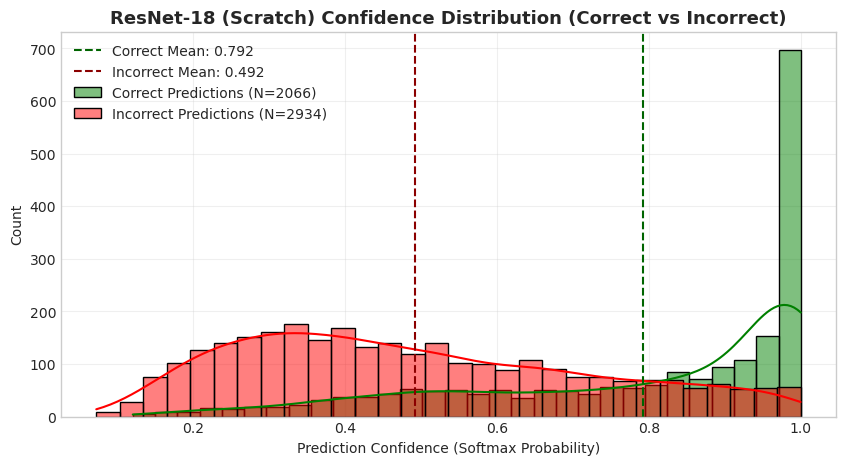

Average forecast confidence (overall): 0.6159
The average confidence of predicting correct samples.: 0.7919
Average confidence of prediction error samples: 0.4919


In [65]:
plt.figure(figsize=(10, 5))

# Extracting the confidence of correct and false predictions
correct_confs = df_preds[df_preds['is_correct'] == True]['confidence']
incorrect_confs = df_preds[df_preds['is_correct'] == False]['confidence']

sns.histplot(correct_confs, color='green', label=f'Correct Predictions (N={len(correct_confs)})', kde=True, bins=30, alpha=0.5)
sns.histplot(incorrect_confs, color='red', label=f'Incorrect Predictions (N={len(incorrect_confs)})', kde=True, bins=30, alpha=0.5)

if len(correct_confs) > 0:
    plt.axvline(x=correct_confs.mean(), color='darkgreen', linestyle='--', label=f'Correct Mean: {correct_confs.mean():.3f}')
if len(incorrect_confs) > 0:
    plt.axvline(x=incorrect_confs.mean(), color='darkred', linestyle='--', label=f'Incorrect Mean: {incorrect_confs.mean():.3f}')

plt.title('ResNet-18 (Scratch) Confidence Distribution (Correct vs Incorrect)', fontsize=13, fontweight='bold')
plt.xlabel('Prediction Confidence (Softmax Probability)')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(EXP_DIR, "resnet18_scratch_confidence_distribution.png"), dpi=300)
plt.show()

print(f"Average forecast confidence (overall): {df_preds['confidence'].mean():.4f}")
print(f"The average confidence of predicting correct samples.: {correct_confs.mean():.4f}" if len(correct_confs) > 0 else "No correct sample")
print(f"Average confidence of prediction error samples: {incorrect_confs.mean():.4f}" if len(incorrect_confs) > 0 else "Error free sample")

## Accuracy analysis of each category (Per-Class Accuracy Top/Bottom 10)

C:\Users\11625\AppData\Local\Temp\ipykernel_30740\513819521.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
C:\Users\11625\AppData\Local\Temp\ipykernel_30740\513819521.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])


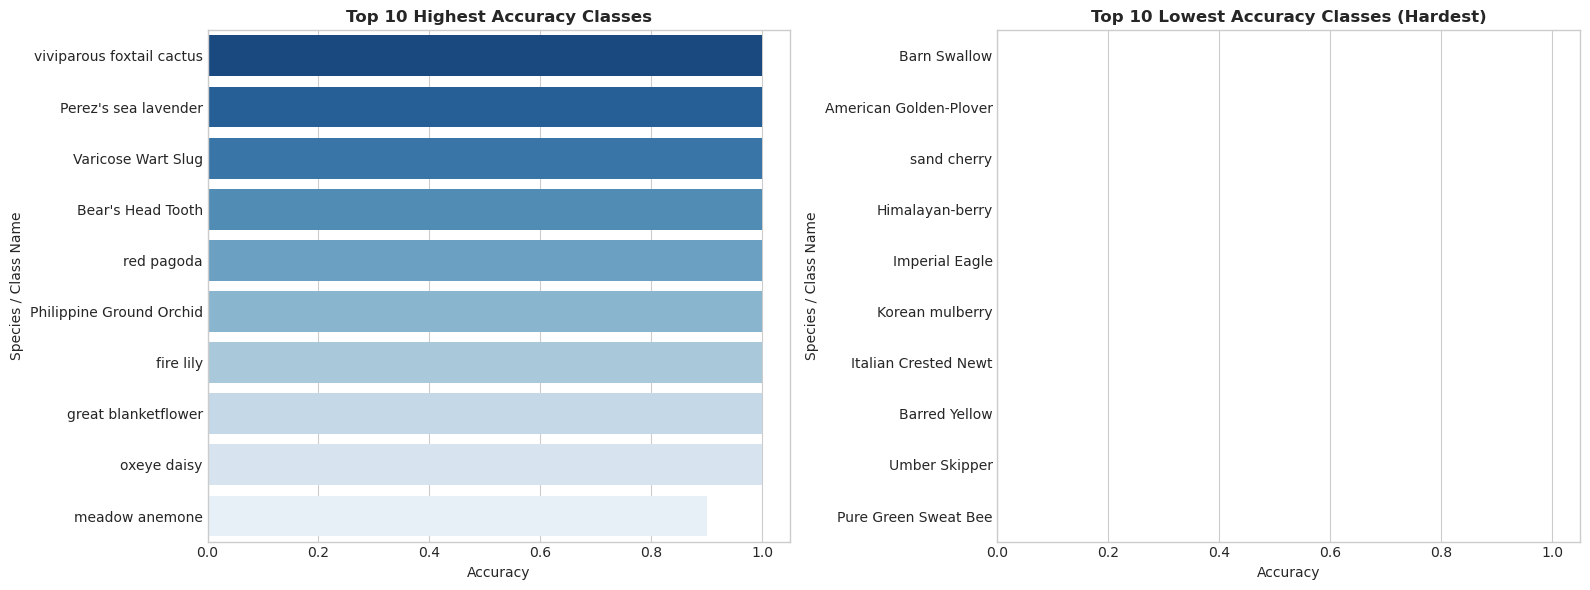

Number of categories with 100% accuracy: 9 / 500
The category with the lowest accuracy 'Barn Swallow' (ID: 177): 0.0%


In [66]:
# Calculate the accuracy of each category
class_acc = df_preds.groupby('true_class')['is_correct'].mean().reset_index()
class_acc.columns = ['class_id', 'accuracy']

# Map class_id to real name.
class_acc['class_name'] = class_acc['class_id'].map(lambda cid: idx_to_name.get(int(cid), f"Class {cid}"))

# Sort by accuracy
class_acc_sorted = class_acc.sort_values(by='accuracy', ascending=False)

top_10 = class_acc_sorted.head(10)
bottom_10 = class_acc_sorted.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 most recognizable category
sns.barplot(data=top_10, x='accuracy', y='class_name', orient='h', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Highest Accuracy Classes', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Accuracy')
axes[0].set_ylabel('Species / Class Name')
axes[0].set_xlim(0, 1.05)

# Bottom 10 is the most difficult category to identify
sns.barplot(data=bottom_10, x='accuracy', y='class_name', orient='h', palette='Reds_r', ax=axes[1])
axes[1].set_title('Top 10 Lowest Accuracy Classes (Hardest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Accuracy')
axes[1].set_ylabel('Species / Class Name')
axes[1].set_xlim(0, 1.05)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_scratch_per_class_accuracy.png"), dpi=300)
plt.show()

print(f"Number of categories with 100% accuracy: {(class_acc['accuracy'] == 1.0).sum()} / {len(class_acc)}")
print(f"The category with the lowest accuracy '{bottom_10.iloc[0]['class_name']}' (ID: {bottom_10.iloc[0]['class_id']}): {bottom_10.iloc[0]['accuracy']*100:.1f}%")

## Full Confusion Matrix Heatmap

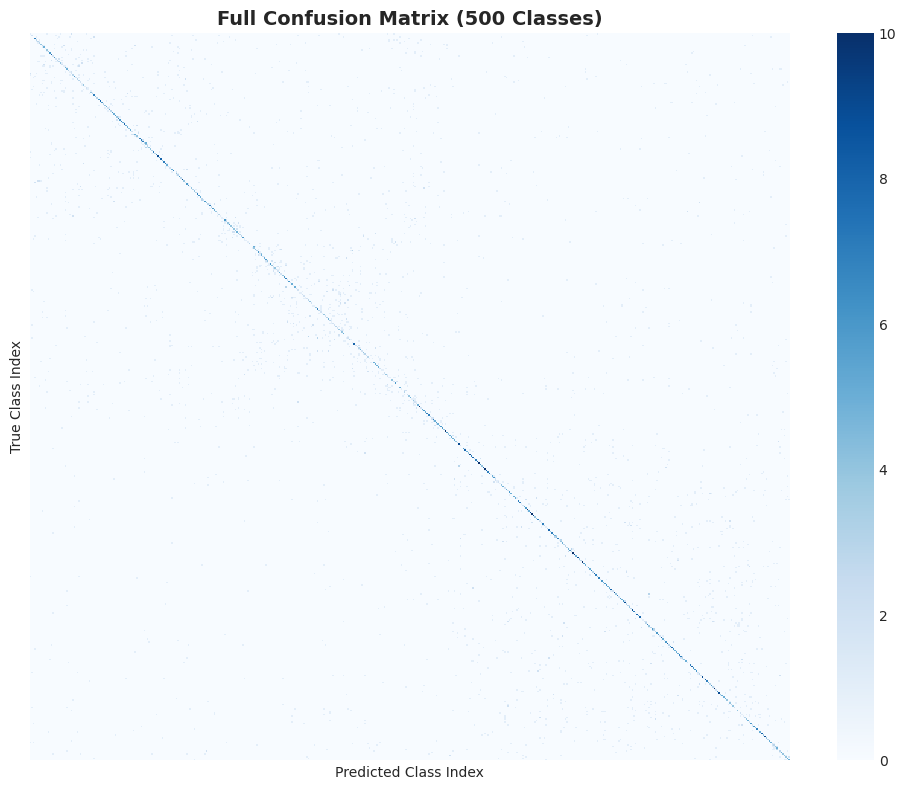

Confusion matrix dimension: (500, 500) (True x Pred)


In [67]:
# Get all the existing category index sets
unique_labels = sorted(list(set(df_preds['true_class']).union(set(df_preds['predicted_class']))))

# Calculate all-class confusion matrix
cm_full = confusion_matrix(df_preds['true_class'], df_preds['predicted_class'], labels=unique_labels)

# Drawing total confusion matrix thermal diagram
plt.figure(figsize=(10, 8))
sns.heatmap(cm_full, cmap="Blues", cbar=True, xticklabels=False, yticklabels=False)
plt.title(f'Full Confusion Matrix ({len(unique_labels)} Classes)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class Index')
plt.ylabel('True Class Index')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_scratch_full_confusion_matrix.png"), dpi=300)
plt.show()

print(f"Confusion matrix dimension: {cm_full.shape} (True x Pred)")

## Deep analysis of weak categories and subset confusion matrix (Hardest Classes & Macro F1 Analysis)

Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy
 class_id              class_name  accuracy  precision  recall  f1-score
      208      Warbling White-eye       0.0        0.0     0.0       0.0
      225             Canada Lynx       0.0        0.0     0.0       0.0
      207 Ash-throated Flycatcher       0.0        0.0     0.0       0.0
      224                  Culpeo       0.0        0.0     0.0       0.0
      237  Texas Alligator Lizard       0.0        0.0     0.0       0.0
      177            Barn Swallow       0.0        0.0     0.0       0.0
      157  American Golden-Plover       0.0        0.0     0.0       0.0
      464             sand cherry       0.0        0.0     0.0       0.0
      466         Himalayan-berry       0.0        0.0     0.0       0.0
      146          Imperial Eagle       0.0        0.0     0.0       0.0
      459         Korean mulberry       0.0        0.0     0.0       0.0
      145    Italian Crested Newt       0.0       

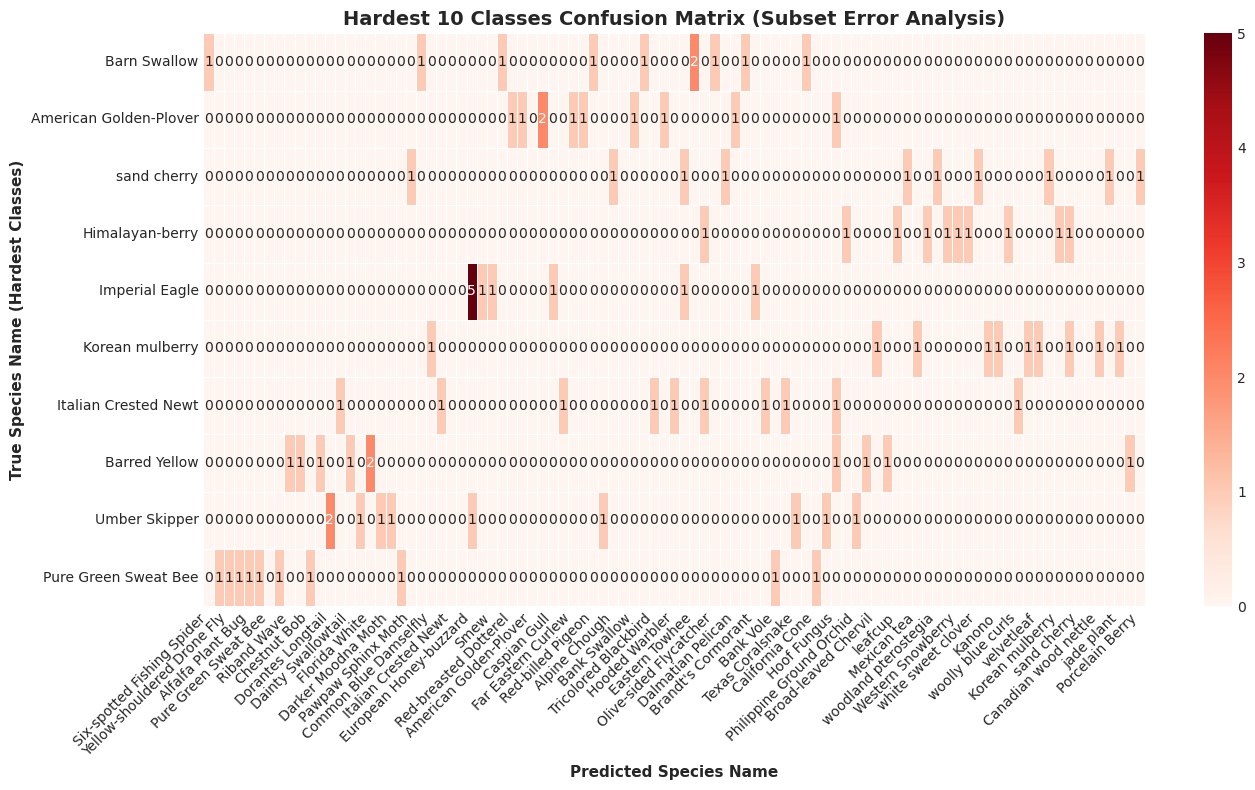

In [68]:
# Extracting the Top 15 vulnerable categories with the lowest accuracy
hardest_classes_df = class_acc_sorted.tail(15).copy()

# Generate a global classification report and extract precision, recall and f1.
report_dict = classification_report(
    df_preds['true_class'], 
    df_preds['predicted_class'], 
    output_dict=True, 
    zero_division=0
)

hardest_classes_df['precision'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('precision', 0.0))
hardest_classes_df['recall'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('recall', 0.0))
hardest_classes_df['f1-score'] = hardest_classes_df['class_id'].apply(lambda cid: report_dict.get(str(cid), {}).get('f1-score', 0.0))

print("="*85)
print("Depth Analysis of Fine-grained Macro Indicators of Top 15 Lowest Accuracy")
print("="*85)
display_cols = ['class_id', 'class_name', 'accuracy', 'precision', 'recall', 'f1-score']
print(hardest_classes_df[display_cols].to_string(index=False))
print("="*85)

# Extracting Top 10 Vulnerable Categories and Constructing Subset Confusion Matrix
hardest_10_ids = class_acc_sorted.tail(10)['class_id'].tolist()
sub_preds = df_preds[df_preds['true_class'].isin(hardest_10_ids)].copy()

# Get the set of all prediction categories involved in the subset (including misjudgment categories)
relevant_pred_ids = sorted(list(set(sub_preds['true_class']).union(set(sub_preds['predicted_class']))))

# Computing subset confusion matrix
cm_sub = confusion_matrix(sub_preds['true_class'], sub_preds['predicted_class'], labels=relevant_pred_ids)

# Convert names and format DataFrame drawings.
row_names = [idx_to_name.get(int(i), f"Class {i}") for i in hardest_10_ids]
col_names = [idx_to_name.get(int(i), f"Class {i}") for i in relevant_pred_ids]

sub_matrix_display = pd.DataFrame(cm_sub, index=[idx_to_name.get(int(i), f"Class {i}") for i in relevant_pred_ids], columns=col_names)
sub_matrix_display = sub_matrix_display.loc[row_names]

# 4. Heat map of drawing confusion matrix of weak category subset
plt.figure(figsize=(14, 8))
sns.heatmap(sub_matrix_display, annot=True, fmt="d", cmap="Reds", cbar=True, linewidths=0.5)

plt.title('Hardest 10 Classes Confusion Matrix (Subset Error Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Species Name', fontsize=11, fontweight='bold')
plt.ylabel('True Species Name (Hardest Classes)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "resnet18_scratch_hardest_classes_confusion_matrix.png"), dpi=300)
plt.show()